# Grupo 7 · Clasificación de países según transición energética (área: Energía)
**Machine Learning · Práctica 2 · Entregable 3: guía de código en Python (versión Jupyter Notebook)**
Universidad Nacional de Ingeniería · FIIS · Ciclo 2026-II · Profesor: Dr. Ing. Hilario Aradiel Castañeda

| Integrante | Correo |
|---|---|
| Crisostomo Cahuas, Gabriel Andre | gabriel.crisostomo.c@uni.pe |
| Curto Meneses, Alessandro del Piero | alessandro.curto.m@uni.pe |
| Rubio Zeta, Luis Miguel | luis.rubio.z@uni.pe |

**Pregunta de fondo:** ¿se puede saber en qué etapa de la transición energética está un país
*antes* de conocer su matriz eléctrica? Clasificamos cada país y año en una de tres etapas
(inicial, intermedia o avanzada) con 23 predictores medidos el año anterior.

Este notebook tiene **el mismo código que `main.py`** y da los mismos resultados. Trabajamos
las dos últimas fases de CRISP-ML(Q) antes del despliegue:

| Fase | Qué hacemos |
|---|---|
| 4 · Modelado | Naive Bayes (el modelo asignado a nuestro grupo) y doce rivales, más un clasificador trivial |
| 5 · Evaluación | una sola medición en 2020-2024, métricas de calidad, intervalos de confianza y errores |

Además respondemos con nuestros propios datos las preguntas de los **capítulos 2 y 3** de la guía.

> Para ejecutarlo: **Kernel → Restart Kernel and Run All Cells**. Tarda unos minutos, casi
> todo en el paso 4.


## Paso 0. Importación de librerías
Las mismas de `main.py` más `IPython.display`, que sirve para mostrar tablas y figuras dentro del notebook. `matplotlib` dibuja en modo *Agg* (sin ventanas): las figuras se guardan en PNG y luego se muestran con `Image`.

In [1]:
# =============================================================================
# PASO 0. IMPORTACIÓN DE LIBRERÍAS
# =============================================================================
# --- Biblioteca estándar de Python (no requiere instalación) -----------------
import argparse                     # opciones de la línea de comandos (--rapido, --n-jobs)
import json                         # guardar los mejores hiperparámetros
import platform                     # versión de Python, que queda registrada en los controles
import sys                          # código de salida del programa
import time                         # medir el tiempo de entrenamiento de cada modelo
import warnings                     # silenciar avisos repetidos de convergencia
from pathlib import Path            # rutas que funcionan en Windows, Linux y macOS
# --- Librerías externas (se instalan con: pip install -r requirements.txt) ---
import numpy as np                  # cálculo numérico y números al azar reproducibles
import pandas as pd                 # tablas de datos (DataFrame)
import matplotlib                   # gráficos
matplotlib.use("Agg")               # dibuja sin abrir ventanas; las figuras se guardan en PNG
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import joblib                       # guardar los modelos entrenados en resultados/modelos
from scipy.stats import binomtest   # prueba exacta de McNemar
# --- scikit-learn: todo el aprendizaje automático ----------------------------
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier,
                              HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score,
                             balanced_accuracy_score, confusion_matrix, f1_score,
                             log_loss, normalized_mutual_info_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import (GridSearchCV, PredefinedSplit,
                                     StratifiedShuffleSplit)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PowerTransformer, RobustScaler,
                                   StandardScaler)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [2]:
# Solo en el notebook: para mostrar tablas, textos y figuras en pantalla
from IPython.display import display, Markdown, Image

## Paso 1. Parámetros del proyecto
Rutas, semilla, predictores, criterio de éxito, nombres de los modelos y estilo de las figuras. En `main.py` las opciones `--rapido` y `--n-jobs` se pasan por consola; aquí se cambian en la celda de opciones.

In [3]:
# Opciones de ejecución (equivalen a los argumentos de main.py)
RAPIDO = False   # True: rejillas reducidas, solo para comprobar que todo corre
N_JOBS = 1       # núcleos para la búsqueda en rejilla (1 funciona igual en Windows)

In [4]:
# =============================================================================
# PASO 1. PARÁMETROS DEL PROYECTO
# =============================================================================
# Carpeta del proyecto. En Jupyter no existe __file__, por eso se usa la
# carpeta actual (la carpeta donde está main.ipynb).
RAIZ = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
CARPETA_DATOS = RAIZ / "datos"                          # entradas (no se modifican)
CARPETA_TABLAS = RAIZ / "resultados" / "tablas"         # tablas CSV y JSON
CARPETA_FIGURAS = RAIZ / "resultados" / "figuras"       # figuras PNG del artículo
CARPETA_MODELOS = RAIZ / "resultados" / "modelos"       # modelos finales (joblib)
CARPETA_REPORTES = RAIZ / "resultados" / "reportes"     # controles y valores para el paper
ARCHIVO_DATOS = CARPETA_DATOS / "etapas_transicion_preparado.csv"
ARCHIVO_AUDITORIA = CARPETA_DATOS / "etapas_auditoria.csv"
# Semilla única: con ella dos corridas dan exactamente los mismos resultados.
SEMILLA = 42
# Variable objetivo y nombres de las tres etapas
OBJETIVO = "etapa_num"
ETAPAS = ["Inicial", "Intermedia", "Avanzada"]
CLASES = [0, 1, 2]
# Los 11 indicadores continuos, medidos el año ANTERIOR al que se predice.
# Son los únicos que se usan en PCA, NMF, t-SNE y agrupamiento (capítulo 3).
CONTINUOS = [
    "pib_pc_log_ant", "poblacion_log_ant", "urbano_pct_ant", "industria_pct_ant",
    "renovable_pct_ant", "co2_pc_log_ant", "energia_pc_log_ant",
    "consumo_elec_pc_log_ant", "var_pib_pc_pct_ant", "var_urbano_pp_ant",
    "var3_renovable_pp_ant",
]
# Los 23 predictores del modelado: los 11 continuos + el año + 7 regiones + 4 ingresos.
PREDICTORES = CONTINUOS + ["anio_relativo"] + [
    "region_africa_subsahariana", "region_america_latina_caribe",
    "region_america_norte", "region_asia_oriental_pacifico", "region_asia_sur",
    "region_europa_asia_central", "region_medio_oriente_norte_africa",
    "ingreso_alto", "ingreso_medio_alto", "ingreso_medio_bajo", "ingreso_bajo",
]
# Columnas que NUNCA pueden ser predictores: identifican al país, dicen el año
# real, repiten la etiqueta o marcan qué valores se imputaron.
PROHIBIDAS = ["codigo_iso3", "nombre_pais", "region", "grupo_ingreso", "anio",
              "etapa", "etapa_num", "conjunto"]
# Partición temporal: ya viene en la columna 'conjunto' del archivo de entrada.
ANIOS_CONJUNTO = {"entrenamiento": (2004, 2015), "validacion": (2016, 2019),
                  "prueba": (2020, 2024)}
FILAS_CONJUNTO = {"entrenamiento": 2160, "validacion": 720, "prueba": 900}
# Criterio de éxito del proyecto: exactitud balanceada mínima en los años de
# prueba. Un clasificador al azar llegaría a 0,333.
CRITERIO_EXITO = 0.75
# Parámetros de la evaluación
REMUESTREOS = 1000          # repeticiones del bootstrap para el intervalo de confianza
ALFA = 0.05                 # nivel de significación de la prueba de McNemar
REPETICIONES_PERM = 10      # repeticiones de la importancia por permutación
UMBRAL_CERCA = 5.0          # "cerca del umbral" = a menos de 5 puntos de 30, 60 o 90
# Nombre corto de cada modelo. El ORDEN de esta lista es el orden de las tablas
# del artículo, así que no debe cambiarse.
ORDEN_MODELOS = [
    "Naive Bayes (base)", "Regresión logística", "k-NN", "Árbol de decisión",
    "Bosque aleatorio", "Extra Trees", "Gradient Boosting",
    "Hist. Gradient Boosting", "AdaBoost", "SVM RBF", "SVM lineal", "LDA",
    "Red neuronal MLP", "Clasificador trivial",
]
MODELO_ASIGNADO = "Naive Bayes (base)"      # el que nos tocó como grupo 7
MODELO_TRIVIAL = "Clasificador trivial"     # línea base; no cuenta entre los rivales
MODELO_LOGISTICA = "Regresión logística"    # referencia de probabilidades bien calibradas
# Nombre de cada modelo en inglés (el artículo lleva una portada en inglés).
NOMBRES_INGLES = {
    "Naive Bayes (base)": "Naive Bayes", "Regresión logística": "Logistic regression",
    "k-NN": "k-NN", "Árbol de decisión": "Decision tree",
    "Bosque aleatorio": "Random forest", "Extra Trees": "Extra Trees",
    "Gradient Boosting": "Gradient Boosting",
    "Hist. Gradient Boosting": "Histogram Gradient Boosting", "AdaBoost": "AdaBoost",
    "SVM RBF": "RBF SVM", "SVM lineal": "Linear SVM", "LDA": "LDA",
    "Red neuronal MLP": "MLP neural network", "Clasificador trivial": "Majority baseline",
}
# Nombre legible de cada predictor, para el texto del artículo.
NOMBRES_LEGIBLES = {
    "pib_pc_log_ant": "PIB per cápita (log)",
    "poblacion_log_ant": "Población (log)",
    "urbano_pct_ant": "Población urbana (%)",
    "industria_pct_ant": "Industria (% del PIB)",
    "renovable_pct_ant": "Energía renovable (%)",
    "co2_pc_log_ant": "CO2 per cápita (log)",
    "energia_pc_log_ant": "Energía per cápita (log)",
    "consumo_elec_pc_log_ant": "Electricidad per cápita (log)",
    "var_pib_pc_pct_ant": "Variación del PIB per cápita (%)",
    "var_urbano_pp_ant": "Variación de la población urbana (p.p.)",
    "var3_renovable_pp_ant": "Variación renovable de 3 años (p.p.)",
    "anio_relativo": "Año relativo",
    "region_africa_subsahariana": "Región: África subsahariana",
    "region_america_latina_caribe": "Región: América Latina y el Caribe",
    "region_america_norte": "Región: América del Norte",
    "region_asia_oriental_pacifico": "Región: Asia oriental y el Pacífico",
    "region_asia_sur": "Región: Asia meridional",
    "region_europa_asia_central": "Región: Europa y Asia central",
    "region_medio_oriente_norte_africa": "Región: Medio Oriente y norte de África",
    "ingreso_alto": "Ingreso alto", "ingreso_medio_alto": "Ingreso medio alto",
    "ingreso_medio_bajo": "Ingreso medio bajo", "ingreso_bajo": "Ingreso bajo",
}
# Nombre aún más corto, solo para que quepa en las figuras de una columna.
NOMBRES_FIGURA = {
    "pib_pc_log_ant": "PIB pc (log)", "poblacion_log_ant": "Población (log)",
    "urbano_pct_ant": "Urbana (%)", "industria_pct_ant": "Industria (%)",
    "renovable_pct_ant": "Renovable (%)", "co2_pc_log_ant": "CO2 pc (log)",
    "energia_pc_log_ant": "Energía pc (log)",
    "consumo_elec_pc_log_ant": "Electricidad pc (log)",
    "var_pib_pc_pct_ant": "Var. PIB pc (%)", "var_urbano_pp_ant": "Var. urbana (p.p.)",
    "var3_renovable_pp_ant": "Var. renov. 3a (p.p.)", "anio_relativo": "Año relativo",
    "region_africa_subsahariana": "Reg. África subs.",
    "region_america_latina_caribe": "Reg. Am. Latina",
    "region_america_norte": "Reg. Am. del Norte",
    "region_asia_oriental_pacifico": "Reg. Asia oriental",
    "region_asia_sur": "Reg. Asia merid.",
    "region_europa_asia_central": "Reg. Europa y Asia c.",
    "region_medio_oriente_norte_africa": "Reg. Medio Oriente",
    "ingreso_alto": "Ingreso alto", "ingreso_medio_alto": "Ingreso medio alto",
    "ingreso_medio_bajo": "Ingreso medio bajo", "ingreso_bajo": "Ingreso bajo",
}
# La región de Medio Oriente tiene un nombre muy largo en los datos del Banco
# Mundial; en las tablas del artículo se usa la versión corta.
REGION_CORTA = {"Medio Oriente, norte de África, Afganistán y Pakistán":
                "Medio Oriente y norte de África"}
ORDEN_REGIONES = ["África subsahariana", "América Latina y el Caribe",
                  "América del Norte", "Asia oriental y el Pacífico",
                  "Asia meridional", "Europa y Asia central",
                  "Medio Oriente y norte de África"]
# --- Estilo de las figuras: deben entrar en una columna del artículo ---------
ANCHO_FIGURA = 3.35                 # pulgadas: ancho de una columna de la plantilla LACCEI
PPP = 300                           # puntos por pulgada exigidos por la plantilla
COLOR_ETAPA = {0: "#d1495b", 1: "#edae49", 2: "#00798c"}    # inicial, intermedia, avanzada
AZUL, GRIS = "#30638e", "#8d99ae"                           # colores de apoyo
COLOR_NB = "#003d5b"                                        # el modelo asignado, resaltado
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.5,
    "figure.dpi": PPP, "savefig.dpi": PPP, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
})
# Avisos que no aportan nada y solo ensucian la consola (convergencia del MLP, etc.).
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*did not converge.*")
# scikit-learn 1.9 avisa de que SVC(probability=True) quedará obsoleto en la 1.11;
# el protocolo del artículo lo usa tal cual, así que el aviso solo haría ruido.
warnings.filterwarnings("ignore", message=".*probability.*deprecated.*")
# Contador de usos del conjunto de prueba, uno por modelo. Lo revisa el control
# de calidad: cada modelo debe medirse en prueba UNA SOLA VEZ.
USOS_DE_PRUEBA: dict[str, int] = {}

## Paso 2. Funciones de apoyo
Mensajes de avance, creación de carpetas, guardado de tablas y figuras, formato de los números con coma decimal y la función que mide un modelo en los años de prueba (la única que toca la prueba).

In [5]:
# =============================================================================
# PASO 2. FUNCIONES DE APOYO
# =============================================================================
def seccion(texto: str) -> None:
    """Imprime un título de sección para seguir el avance en la consola."""
    print("\n" + "=" * 78 + f"\n {texto}\n" + "=" * 78)

In [6]:
def nota(texto: str) -> None:
    """Imprime un mensaje de avance con sangría."""
    print(f"   - {texto}")

In [7]:
def preparar_carpetas() -> None:
    """Crea las carpetas de salida si todavía no existen."""
    for carpeta in (CARPETA_TABLAS, CARPETA_FIGURAS, CARPETA_MODELOS, CARPETA_REPORTES):
        carpeta.mkdir(parents=True, exist_ok=True)

In [8]:
def guardar_tabla(df: pd.DataFrame, nombre: str) -> None:
    """Guarda una tabla en resultados/tablas con codificación UTF-8."""
    df.to_csv(CARPETA_TABLAS / nombre, index=False, encoding="utf-8")
    nota(f"tabla guardada: resultados/tablas/{nombre}")

In [9]:
def guardar_figura(fig, nombre: str) -> None:
    """Guarda una figura en resultados/figuras a 300 ppp y libera la memoria."""
    fig.savefig(CARPETA_FIGURAS / nombre, bbox_inches="tight", dpi=PPP)
    plt.close(fig)
    nota(f"figura guardada: resultados/figuras/{nombre}")

In [10]:
def tabla_md(df: pd.DataFrame) -> str:
    """Convierte un DataFrame en una tabla Markdown (sin depender de 'tabulate')."""
    columnas = [str(c) for c in df.columns]
    filas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    for _, fila in df.iterrows():
        filas.append("| " + " | ".join(str(v) for v in fila.values) + " |")
    return "\n".join(filas)

In [11]:
# --- Formato de los números tal como los pide el artículo (coma decimal) -----
def num(x: float, decimales: int = 3) -> str:
    """0.8213 -> '0,821'. Las métricas del artículo llevan tres decimales."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "-"
    return f"{x:.{decimales}f}".replace(".", ",")

In [12]:
def pct(x: float, decimales: int = 1) -> str:
    """0.873 -> '87,3 %'. El valor entra como proporción entre 0 y 1."""
    return f"{100 * x:.{decimales}f}".replace(".", ",") + " %"

In [13]:
def puntos(x: float) -> str:
    """Diferencia entre dos métricas expresada en puntos: 0.0123 -> '+1,2'."""
    return f"{100 * x:+.1f}".replace(".", ",")

In [14]:
def intervalo(lo: float, hi: float) -> str:
    """Intervalo de confianza con el guion largo que usa el artículo."""
    return f"{num(lo)}–{num(hi)}"

In [15]:
def legible(columna: str) -> str:
    """Nombre de un predictor tal como se lee en el texto del artículo."""
    return NOMBRES_LEGIBLES.get(columna, columna)

In [16]:
def lista_y(nombres: list[str]) -> str:
    """['a','b','c'] -> 'a, b y c' (como se escribe una enumeración en español)."""
    if len(nombres) == 1:
        return nombres[0]
    return ", ".join(nombres[:-1]) + " y " + nombres[-1]

In [17]:
def nombre_corto(modelo: str) -> str:
    """En las figuras, 'Naive Bayes (base)' se lee mejor como 'Naive Bayes'."""
    return "Naive Bayes" if modelo == MODELO_ASIGNADO else modelo

In [18]:
def ejes_con_coma(eje, en_x: bool = True, en_y: bool = True) -> None:
    """Pone coma decimal en las marcas de los ejes, como se escribe en español."""
    formato = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
    if en_x:
        eje.xaxis.set_major_formatter(formato)
    if en_y:
        eje.yaxis.set_major_formatter(formato)

In [19]:
def metricas_en_prueba(nombre: str, modelo, X, y) -> dict:
    """
    Mide UN modelo en los años de prueba y anota ese uso en USOS_DE_PRUEBA.

    Es el único lugar del programa donde se calculan métricas sobre la prueba:
    así el control de calidad puede comprobar que cada modelo la usó una sola
    vez y que ningún modelo se eligió mirando esos años.

    Devuelve las métricas pedidas por la guía: exactitud balanceada, F1 macro,
    exactitud, recall de cada etapa, pérdida logarítmica y AUC multiclase.
    """
    USOS_DE_PRUEBA[nombre] = USOS_DE_PRUEBA.get(nombre, 0) + 1
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)
    recalls = recall_score(y, pred, labels=CLASES, average=None, zero_division=0)
    return {
        "eb_prueba": balanced_accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "exactitud": accuracy_score(y, pred),
        "recall_inicial": recalls[0],
        "recall_intermedia": recalls[1],
        "recall_avanzada": recalls[2],
        "log_loss": log_loss(y, proba, labels=CLASES),
        "auc_ovr_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "_pred": pred,
        "_proba": proba,
    }

In [20]:
# Crea resultados/tablas, figuras, modelos y reportes
preparar_carpetas()

## Paso 3. Carga y verificación de los datos
Se lee el conjunto ya preparado y etiquetado y se parte en entrenamiento (2004-2015), validación (2016-2019) y prueba (2020-2024). **No se limpia nada y no se cambia la etiqueta.** Los `assert` comprueban que el archivo es el que esperamos: forma, ausencia de faltantes, 23 predictores y años de cada conjunto.

**Resultado esperado:** 3 780 filas × 39 columnas, 180 países y 2 160 / 720 / 900 filas.

In [21]:
# =============================================================================
# PASO 3. CARGA Y VERIFICACIÓN DE LOS DATOS
# =============================================================================
def cargar_datos() -> dict:
    """
    Lee el conjunto ya preparado y lo parte en entrenamiento, validación y prueba.

    No limpia nada y no toca la etiqueta: ese trabajo ya está hecho y el archivo
    de entrada se usa tal como viene. Lo que sí hace es comprobar con 'assert'
    que el archivo es el que esperamos; si algo no cuadra, el programa se
    detiene antes de entrenar.

    Resultado esperado:
      * 3 780 filas x 39 columnas, 180 países, 2004-2024, 0 faltantes;
      * 23 predictores presentes y ninguna columna prohibida entre ellos;
      * 2 160 filas de entrenamiento (2004-2015), 720 de validación (2016-2019)
        y 900 de prueba (2020-2024).
    """
    seccion("PASO 3. DATOS DE ENTRADA (ya preparados y etiquetados)")
    df = pd.read_csv(ARCHIVO_DATOS, encoding="utf-8")

    # --- Verificaciones de forma -------------------------------------------
    assert df.shape == (3780, 39), f"se esperaban 3780x39 y llegó {df.shape}"
    assert df.isna().sum().sum() == 0, "el conjunto no debería tener faltantes"
    assert df["codigo_iso3"].nunique() == 180, "se esperaban 180 países"
    assert len(PREDICTORES) == 23, "los predictores del modelado deben ser 23"
    faltan = [c for c in PREDICTORES if c not in df.columns]
    assert not faltan, f"faltan predictores en el archivo: {faltan}"

    # --- Ningún predictor puede identificar al país ni revelar la etiqueta ---
    coladas = [c for c in PREDICTORES if c in PROHIBIDAS or c.startswith("bandera_imp_")]
    assert not coladas, f"predictores prohibidos: {coladas}"

    # --- Los años de cada conjunto no se mezclan ----------------------------
    for conjunto, (anio_ini, anio_fin) in ANIOS_CONJUNTO.items():
        anios = df.loc[df["conjunto"] == conjunto, "anio"]
        assert anios.min() == anio_ini and anios.max() == anio_fin, \
            f"los años de {conjunto} no son {anio_ini}-{anio_fin}"
        assert len(anios) == FILAS_CONJUNTO[conjunto], \
            f"{conjunto} debería tener {FILAS_CONJUNTO[conjunto]} filas"

    partes = {}
    for conjunto in ANIOS_CONJUNTO:
        sub = df[df["conjunto"] == conjunto]
        partes[conjunto] = (sub[PREDICTORES].to_numpy(dtype=float),
                            sub[OBJETIVO].to_numpy(dtype=int), sub)

    X_tr, y_tr, df_tr = partes["entrenamiento"]
    X_va, y_va, df_va = partes["validacion"]
    X_pr, y_pr, df_pr = partes["prueba"]

    # Entrenamiento + validación en una sola matriz. Con PredefinedSplit la
    # búsqueda de hiperparámetros entrena con las filas marcadas -1 (los años
    # 2004-2015) y mide con las marcadas 0 (2016-2019): nunca mezcla los años.
    X_tv = np.vstack([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])
    marca = np.concatenate([np.full(len(y_tr), -1), np.zeros(len(y_va), dtype=int)])
    particion = PredefinedSplit(marca)

    nota(f"{df.shape[0]} filas x {df.shape[1]} columnas, "
         f"{df['codigo_iso3'].nunique()} países, {df['anio'].min()}-{df['anio'].max()}")
    nota(f"predictores: {len(PREDICTORES)} ({len(CONTINUOS)} continuos, 1 de tiempo, "
         "7 de región y 4 de ingreso)")
    for conjunto, (anio_ini, anio_fin) in ANIOS_CONJUNTO.items():
        sub = df[df["conjunto"] == conjunto]
        reparto = sub[OBJETIVO].value_counts(normalize=True).sort_index()
        nota(f"{conjunto:>13}: {len(sub):4d} filas ({anio_ini}-{anio_fin}), "
             f"avanzada {pct(reparto.get(2, 0.0))}")
    nota("2025 no se usa: el Banco Mundial aún no publica el acceso a la "
         "electricidad de ese año")

    return {"df": df, "X_tr": X_tr, "y_tr": y_tr, "X_va": X_va, "y_va": y_va,
            "X_pr": X_pr, "y_pr": y_pr, "X_tv": X_tv, "y_tv": y_tv,
            "particion": particion, "df_prueba": df_pr, "df_entrenamiento": df_tr,
            "df_validacion": df_va}

Se cargan los datos y se muestran las primeras filas.

In [22]:
datos = cargar_datos()
display(datos["df"].head(5))


 PASO 3. DATOS DE ENTRADA (ya preparados y etiquetados)
   - 3780 filas x 39 columnas, 180 países, 2004-2024
   - predictores: 23 (11 continuos, 1 de tiempo, 7 de región y 4 de ingreso)
   - entrenamiento: 2160 filas (2004-2015), avanzada 12,9 %
   -    validacion:  720 filas (2016-2019), avanzada 19,0 %
   -        prueba:  900 filas (2020-2024), avanzada 22,9 %
   - 2025 no se usa: el Banco Mundial aún no publica el acceso a la electricidad de ese año


,codigo_iso3,nombre_pais,region,grupo_ingreso,anio,etapa,etapa_num,pib_pc_log_ant,poblacion_log_ant,urbano_pct_ant,...,ingreso_bajo,bandera_imp_pib_pc,bandera_imp_poblacion,bandera_imp_urbano_pct,bandera_imp_industria_pct,bandera_imp_renovable_pct,bandera_imp_co2_pc,bandera_imp_energia_pc,bandera_imp_consumo_elec_pc,conjunto
0,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2004,inicial,0,10.258564,11.441730,65.198292,...,0,0,0,0,0,0,0,0,0,entrenamiento
1,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2005,inicial,0,10.307611,11.463084,65.088653,...,0,0,0,0,0,0,0,0,0,entrenamiento
2,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2006,inicial,0,10.277865,11.488991,64.958023,...,0,0,0,0,0,0,0,0,0,entrenamiento
3,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2007,inicial,0,10.271109,11.506958,64.811270,...,0,0,0,0,0,0,0,0,0,entrenamiento
4,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2008,inicial,0,10.294070,11.514424,64.653266,...,0,0,0,0,0,0,0,0,0,entrenamiento


## Paso 4. Fase 4 de CRISP-ML(Q): modelado
Se entrenan Naive Bayes (el modelo asignado a nuestro grupo) y doce rivales, más un clasificador trivial. Para cada uno: búsqueda en rejilla con los años de validación, métricas de validación, modelo final entrenado con 2004-2019 y una sola medición en 2020-2024.

**Resultado esperado:** `comparacion_modelos.csv`, `mejores_parametros.json` y `variantes_naive_bayes.csv`. Es el paso más lento (unos minutos).

In [23]:
# =============================================================================
# PASO 4. FASE 4 DE CRISP-ML(Q): MODELADO
# =============================================================================
def construir_modelos() -> dict:
    """
    Devuelve, para cada modelo, su estimador y la rejilla de hiperparámetros.

    Cada modelo es un 'pipeline': los que dependen de distancias o de márgenes
    (k-NN, las dos SVM, la regresión logística y la red neuronal) llevan
    estandarizado delante, porque sin él una variable con números grandes pesa
    más que las demás. Los árboles no lo necesitan: sus cortes solo miran el
    orden de los valores.

    El escalador se ajusta DENTRO del pipeline, así que durante la búsqueda de
    hiperparámetros aprende solo de los años de entrenamiento y nunca ve los de
    validación ni los de prueba (evita la fuga de información).
    """
    tercios = [1 / 3, 1 / 3, 1 / 3]     # probabilidades a priori iguales para las 3 etapas
    rejilla_arboles = {                 # la misma para bosque aleatorio y Extra Trees
        "max_depth": [None, 8, 12], "min_samples_leaf": [1, 3, 5],
        "max_features": ["sqrt", 0.5], "class_weight": [None, "balanced"],
    }
    return {
        # El modelo asignado al grupo. Se prueban dos cosas más: transformar las
        # variables con Yeo-Johnson para acercarlas a una normal (que es lo que
        # Naive Bayes gaussiano supone) y darle la misma probabilidad a priori a
        # las tres etapas, porque en el entrenamiento hay pocos países avanzados.
        "Naive Bayes (base)": (
            Pipeline([("transf", "passthrough"), ("modelo", GaussianNB())]),
            {"transf": ["passthrough", PowerTransformer()],
             "modelo__priors": [None, tercios],
             "modelo__var_smoothing": np.logspace(-11, -1, 11)},
        ),
        "Regresión logística": (
            Pipeline([("escalador", StandardScaler()),
                      ("modelo", LogisticRegression(max_iter=5000, random_state=SEMILLA))]),
            {"modelo__C": [0.01, 0.1, 1, 10, 100],
             "modelo__class_weight": [None, "balanced"]},
        ),
        "k-NN": (
            Pipeline([("escalador", StandardScaler()), ("modelo", KNeighborsClassifier())]),
            {"modelo__n_neighbors": [3, 5, 7, 9, 15, 25, 35],
             "modelo__weights": ["uniform", "distance"]},
        ),
        "Árbol de decisión": (
            DecisionTreeClassifier(random_state=SEMILLA),
            {"max_depth": [3, 4, 5, 6, 8, 10, None],
             "min_samples_leaf": [1, 5, 10, 20],
             "class_weight": [None, "balanced"]},
        ),
        "Bosque aleatorio": (
            RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
            dict(rejilla_arboles),
        ),
        "Extra Trees": (
            ExtraTreesClassifier(n_estimators=300, random_state=SEMILLA),
            dict(rejilla_arboles),
        ),
        "Gradient Boosting": (
            GradientBoostingClassifier(random_state=SEMILLA),
            {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1],
             "max_depth": [2, 3]},
        ),
        "Hist. Gradient Boosting": (
            HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA),
            {"learning_rate": [0.05, 0.1], "max_depth": [None, 4],
             "l2_regularization": [0.0, 1.0], "class_weight": [None, "balanced"]},
        ),
        "AdaBoost": (
            AdaBoostClassifier(random_state=SEMILLA),
            {"n_estimators": [100, 300], "learning_rate": [0.1, 0.5, 1.0]},
        ),
        "SVM RBF": (
            Pipeline([("escalador", StandardScaler()),
                      ("modelo", SVC(kernel="rbf", probability=True, random_state=SEMILLA))]),
            {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": ["scale", 0.01, 0.1],
             "modelo__class_weight": [None, "balanced"]},
        ),
        "SVM lineal": (
            Pipeline([("escalador", StandardScaler()),
                      ("modelo", SVC(kernel="linear", probability=True,
                                     random_state=SEMILLA))]),
            {"modelo__C": [0.01, 0.1, 1, 10],
             "modelo__class_weight": [None, "balanced"]},
        ),
        "LDA": (
            LinearDiscriminantAnalysis(),
            [{"solver": ["svd"]}, {"solver": ["lsqr"], "shrinkage": ["auto"]}],
        ),
        "Red neuronal MLP": (
            Pipeline([("escalador", StandardScaler()),
                      ("modelo", MLPClassifier(max_iter=2000, early_stopping=True,
                                               random_state=SEMILLA))]),
            {"modelo__hidden_layer_sizes": [(32,), (64,), (64, 32)],
             "modelo__alpha": [1e-4, 1e-3, 1e-2]},
        ),
        # Línea base obligatoria: predice siempre la etapa más frecuente. No es
        # un rival (no aprende nada); sirve para saber qué significa "acertar".
        "Clasificador trivial": (
            DummyClassifier(strategy="most_frequent"), {},
        ),
    }

In [24]:
def reducir_rejilla(rejilla):
    """Deja un solo valor por hiperparámetro: es la opción --rapido, solo para probar."""
    if isinstance(rejilla, list):
        return [reducir_rejilla(r) for r in rejilla]
    return {clave: list(valores)[:1] for clave, valores in rejilla.items()}

In [25]:
def fase4_modelado(datos: dict, rapido: bool, n_jobs: int) -> dict:
    """
    FASE 4 DE CRISP-ML(Q). Entrena los 13 modelos y el clasificador trivial.

    Para cada modelo se hacen siempre los mismos cuatro pasos:
      1. Búsqueda en rejilla con GridSearchCV y PredefinedSplit: entrena con
         2004-2015 y elige los hiperparámetros por exactitud balanceada en
         2016-2019.
      2. Métricas de validación: con esos hiperparámetros se entrena otra vez
         solo con 2004-2015 y se mide en 2016-2019 (columna EB-V del artículo).
      3. Modelo final: con esos mismos hiperparámetros se entrena con
         2004-2019 (entrenamiento + validación) y se cronometra.
      4. Una sola medición en 2020-2024.

    Resultado esperado:
      * resultados/tablas/comparacion_modelos.csv con las métricas de los 14 modelos;
      * resultados/tablas/mejores_parametros.json con la combinación elegida;
      * resultados/tablas/variantes_naive_bayes.csv con las 4 variantes del modelo asignado;
      * resultados/modelos/*.joblib con el Naive Bayes final y el mejor modelo.
    """
    seccion("PASO 4. FASE 4 DE CRISP-ML(Q) - MODELADO")
    nota(f"búsqueda de hiperparámetros por exactitud balanceada en validación "
         f"(scikit-learn {sklearn.__version__}, semilla {SEMILLA})")
    if rapido:
        nota("MODO --rapido: rejillas reducidas; los números NO son los del artículo")

    X_tr, y_tr = datos["X_tr"], datos["y_tr"]
    X_va, y_va = datos["X_va"], datos["y_va"]
    X_tv, y_tv = datos["X_tv"], datos["y_tv"]
    X_pr, y_pr = datos["X_pr"], datos["y_pr"]

    filas, modelos_finales, mejores_parametros = [], {}, {}
    for nombre in ORDEN_MODELOS:
        estimador, rejilla = construir_modelos()[nombre]
        busqueda = GridSearchCV(
            estimador, reducir_rejilla(rejilla) if rapido else rejilla,
            scoring="balanced_accuracy", cv=datos["particion"], refit=True,
            n_jobs=n_jobs, error_score="raise",
        )
        busqueda.fit(X_tv, y_tv)
        parametros = busqueda.best_params_

        # (2) El mismo modelo entrenado SOLO con los años de entrenamiento: así
        # la exactitud balanceada en validación es comparable entre modelos.
        en_validacion = clone(estimador).set_params(**parametros).fit(X_tr, y_tr)
        eb_validacion = balanced_accuracy_score(y_va, en_validacion.predict(X_va))

        # (3) Modelo final: aprende de todo lo que había antes de la prueba.
        final = clone(estimador).set_params(**parametros)
        reloj = time.perf_counter()
        final.fit(X_tv, y_tv)
        segundos = time.perf_counter() - reloj

        # (4) Única mirada a los años de prueba.
        metricas = metricas_en_prueba(nombre, final, X_pr, y_pr)
        metricas["_modelo"] = nombre
        fila = {"modelo": nombre, "eb_validacion": eb_validacion,
                **{k: v for k, v in metricas.items() if not k.startswith("_")},
                "segundos_entrenamiento": segundos}
        filas.append(fila)
        modelos_finales[nombre] = {"modelo": final, "parametros": parametros,
                                   "pred": metricas["_pred"], "proba": metricas["_proba"]}
        mejores_parametros[nombre] = {k: str(v) for k, v in parametros.items()}
        nota(f"{nombre:<24} EB-V {num(eb_validacion)}  EB-P {num(metricas['eb_prueba'])}  "
             f"({segundos:5.1f} s)")

    comparacion = pd.DataFrame(filas)
    guardar_tabla(comparacion, "comparacion_modelos.csv")
    (CARPETA_TABLAS / "mejores_parametros.json").write_text(
        json.dumps(mejores_parametros, indent=2, ensure_ascii=False), encoding="utf-8")
    nota("tabla guardada: resultados/tablas/mejores_parametros.json")

    variantes = variantes_naive_bayes(datos, modelos_finales[MODELO_ASIGNADO]["parametros"])
    return {"comparacion": comparacion, "modelos": modelos_finales,
            "variantes": variantes}

In [26]:
def variantes_naive_bayes(datos: dict, parametros_finales: dict) -> pd.DataFrame:
    """
    Compara las cuatro variantes del modelo asignado (Tabla V del artículo).

    Las cuatro salen de combinar la transformación (ninguna o Yeo-Johnson) con
    las probabilidades a priori (las de los datos o iguales para las tres
    etapas). Para cada combinación se elige el mejor var_smoothing en los años
    de validación, se reentrena con entrenamiento + validación y se mide una
    vez en prueba.

    Resultado esperado: resultados/tablas/variantes_naive_bayes.csv con cuatro
    filas; la mejor en validación es la que usa el Naive Bayes final.
    """
    nota("variantes de Naive Bayes: transformación x probabilidades a priori")
    tercios = [1 / 3, 1 / 3, 1 / 3]
    combinaciones = [("Ninguna", "De los datos", "passthrough", None),
                     ("Ninguna", "Iguales", "passthrough", tercios),
                     ("Yeo-Johnson", "De los datos", PowerTransformer(), None),
                     ("Yeo-Johnson", "Iguales", PowerTransformer(), tercios)]
    filas = []
    for transformacion, priors, transf, valor_priors in combinaciones:
        base = Pipeline([("transf", transf), ("modelo", GaussianNB(priors=valor_priors))])
        mejor = (-1.0, None)
        for suavizado in np.logspace(-11, -1, 11):
            candidato = clone(base).set_params(modelo__var_smoothing=suavizado)
            candidato.fit(datos["X_tr"], datos["y_tr"])
            eb = balanced_accuracy_score(datos["y_va"], candidato.predict(datos["X_va"]))
            if eb > mejor[0]:               # ante empate se queda el suavizado más pequeño
                mejor = (eb, suavizado)
        eb_validacion, suavizado = mejor
        final = clone(base).set_params(modelo__var_smoothing=suavizado)
        final.fit(datos["X_tv"], datos["y_tv"])
        etiqueta = f"Variante NB: {transformacion} / {priors}"
        metricas = metricas_en_prueba(etiqueta, final, datos["X_pr"], datos["y_pr"])
        filas.append({"transformacion": transformacion, "priors": priors,
                      "var_smoothing": suavizado, "eb_validacion": eb_validacion,
                      "eb_prueba": metricas["eb_prueba"], "log_loss": metricas["log_loss"]})
    variantes = pd.DataFrame(filas)
    guardar_tabla(variantes, "variantes_naive_bayes.csv")

    # La variante que usa el Naive Bayes final es la que ganó la búsqueda en
    # rejilla; aquí se deja escrita tal como aparecerá en el artículo.
    usa_yeo = "PowerTransformer" in str(parametros_finales.get("transf", "passthrough"))
    usa_iguales = parametros_finales.get("modelo__priors") is not None
    suavizado_final = parametros_finales.get("modelo__var_smoothing", float("nan"))
    nota(f"Naive Bayes final: {'Yeo-Johnson' if usa_yeo else 'sin transformación'}, "
         f"priors {'iguales' if usa_iguales else 'de los datos'}, "
         f"var_smoothing = {suavizado_final:.0e}")
    return variantes

Se entrenan los 14 modelos. **Es la celda más lenta.**

In [27]:
modelado = fase4_modelado(datos, RAPIDO, N_JOBS)
display(modelado["comparacion"].round(3))
display(modelado["variantes"].round(3))


 PASO 4. FASE 4 DE CRISP-ML(Q) - MODELADO
   - búsqueda de hiperparámetros por exactitud balanceada en validación (scikit-learn 1.9.1, semilla 42)


   - Naive Bayes (base)       EB-V 0,660  EB-P 0,611  (  0.0 s)


   - Regresión logística      EB-V 0,724  EB-P 0,717  (  0.0 s)


   - k-NN                     EB-V 0,812  EB-P 0,790  (  0.0 s)


   - Árbol de decisión        EB-V 0,795  EB-P 0,773  (  0.0 s)


...

   - SVM lineal               EB-V 0,754  EB-P 0,729  (  4.6 s)
   - LDA                      EB-V 0,693  EB-P 0,662  (  0.0 s)


   - Red neuronal MLP         EB-V 0,771  EB-P 0,798  (  0.5 s)
   - Clasificador trivial     EB-V 0,333  EB-P 0,333  (  0.0 s)
   - tabla guardada: resultados/tablas/comparacion_modelos.csv
   - tabla guardada: resultados/tablas/mejores_parametros.json
   - variantes de Naive Bayes: transformación x probabilidades a priori


   - tabla guardada: resultados/tablas/variantes_naive_bayes.csv
   - Naive Bayes final: sin transformación, priors de los datos, var_smoothing = 1e-02


,modelo,eb_validacion,eb_prueba,f1_macro,exactitud,recall_inicial,recall_intermedia,recall_avanzada,log_loss,auc_ovr_macro,segundos_entrenamiento
0,Naive Bayes (base),0.660,0.611,0.603,0.618,0.679,0.498,0.655,1.068,0.765,0.001
1,Regresión logística,0.724,0.717,0.691,0.708,0.755,0.487,0.908,0.690,0.862,0.029
2,k-NN,0.812,0.790,0.800,0.813,0.911,0.726,0.733,2.822,0.921,0.002
3,Árbol de decisión,0.795,0.773,0.783,0.799,0.892,0.744,0.684,7.249,0.833,0.022
4,Bosque aleatorio,0.861,0.875,0.879,0.886,0.933,0.841,0.850,0.367,0.966,1.283
5,Extra Trees,0.877,0.895,0.903,0.909,0.966,0.856,0.864,0.337,0.972,1.064
6,Gradient Boosting,0.808,0.813,0.821,0.830,0.885,0.812,0.743,0.434,0.946,4.876
7,Hist. Gradient Boosting,0.872,0.872,0.875,0.882,0.938,0.809,0.869,0.363,0.966,2.859
8,AdaBoost,0.663,0.666,0.675,0.689,0.796,0.570,0.631,1.066,0.856,1.384
9,SVM RBF,0.845,0.829,0.838,0.850,0.933,0.787,0.767,0.467,0.937,0.923


,transformacion,priors,var_smoothing,eb_validacion,eb_prueba,log_loss
0,Ninguna,De los datos,0.01,0.660,0.611,1.068
1,Ninguna,Iguales,0.00,0.626,0.633,2.298
2,Yeo-Johnson,De los datos,0.10,0.630,0.659,2.664
3,Yeo-Johnson,Iguales,0.10,0.620,0.628,2.847


## Paso 5. Fase 5 de CRISP-ML(Q): evaluación
Se elige el mejor modelo (mayor exactitud balanceada en prueba, sin contar el trivial) y se explica dónde se equivoca: intervalos de confianza por bootstrap, prueba de McNemar frente a Naive Bayes, matrices de confusión, exactitud por región, errores cerca de los umbrales de la regla e importancia de las variables.

In [28]:
# =============================================================================
# PASO 5. FASE 5 DE CRISP-ML(Q): EVALUACIÓN
# =============================================================================
def intervalo_bootstrap(y_real: np.ndarray, pred: np.ndarray) -> tuple[float, float]:
    """
    Intervalo de confianza del 95 % de la exactitud balanceada, por bootstrap.

    Se vuelven a sortear 1 000 veces las 900 filas de prueba (con reemplazo) y
    se calcula la exactitud balanceada en cada remuestreo; el intervalo son los
    percentiles 2,5 y 97,5. Dice cuánto podría moverse el resultado si nos
    hubiera tocado otra muestra de países y años parecida.
    """
    azar = np.random.RandomState(SEMILLA)       # misma semilla -> mismo intervalo siempre
    n = len(y_real)
    valores = []
    for _ in range(REMUESTREOS):
        indices = azar.randint(0, n, n)
        valores.append(balanced_accuracy_score(y_real[indices], pred[indices]))
    return float(np.percentile(valores, 2.5)), float(np.percentile(valores, 97.5))

In [29]:
def prueba_mcnemar(y_real: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray) -> dict:
    """
    Prueba exacta de McNemar entre dos modelos sobre las MISMAS filas de prueba.

    Solo cuentan las filas en las que los dos modelos no coinciden: b01 son las
    que el modelo A falla y B acierta, y b10 al revés. Si los dos fueran
    igual de buenos, esos desacuerdos se repartirían mitad y mitad; la prueba
    binomial dice qué tan raro sería el reparto observado.
    """
    acierta_a, acierta_b = (pred_a == y_real), (pred_b == y_real)
    b01 = int(np.sum(~acierta_a & acierta_b))   # A falla, B acierta
    b10 = int(np.sum(acierta_a & ~acierta_b))   # A acierta, B falla
    if b01 + b10 == 0:                          # los dos modelos aciertan y fallan igual
        return {"b01": 0, "b10": 0, "p": 1.0, "significativa": False}
    p = binomtest(min(b01, b10), b01 + b10, 0.5).pvalue
    return {"b01": b01, "b10": b10, "p": float(p), "significativa": bool(p < ALFA)}

In [30]:
def exactitud_por_region(df_prueba: pd.DataFrame, y_real: np.ndarray,
                         predicciones: dict) -> pd.DataFrame:
    """
    Exactitud de cada modelo en las siete regiones del Banco Mundial.

    Sirve para ver si los errores se concentran en alguna parte del mundo, que
    es justo lo que importaría a un banco de desarrollo.
    """
    regiones = df_prueba["region"].replace(REGION_CORTA).to_numpy()
    filas = []
    for region in ORDEN_REGIONES:
        donde = regiones == region
        fila = {"region": region, "filas": int(donde.sum())}
        for nombre, pred in predicciones.items():
            fila[nombre] = accuracy_score(y_real[donde], pred[donde]) if donde.any() else np.nan
        filas.append(fila)
    return pd.DataFrame(filas)

In [31]:
def errores_cerca_del_umbral(df_prueba: pd.DataFrame, y_real: np.ndarray,
                             pred: np.ndarray) -> dict:
    """
    ¿Los errores del mejor modelo están donde la regla de la etiqueta es frágil?

    La etapa se decide con dos umbrales: 30 % y 60 % de electricidad baja en
    carbono (promedio de tres años) y 90 % de acceso a la electricidad. Un país
    que está a menos de 5 puntos de un umbral puede cambiar de etapa por una
    diferencia mínima, así que equivocarse ahí es menos grave.
    """
    auditoria = pd.read_csv(ARCHIVO_AUDITORIA, encoding="utf-8",
                            usecols=["codigo_iso3", "anio", "b_promedio_3", "electricidad_pct"])
    unido = df_prueba[["codigo_iso3", "anio"]].merge(auditoria, on=["codigo_iso3", "anio"],
                                                     how="left", validate="one_to_one")
    assert unido["b_promedio_3"].notna().all(), "faltan insumos de la etiqueta en la auditoría"
    b = unido["b_promedio_3"].to_numpy()
    acceso = unido["electricidad_pct"].to_numpy()
    cerca = ((np.abs(b - 30) < UMBRAL_CERCA) | (np.abs(b - 60) < UMBRAL_CERCA)
             | ((b >= 60) & (np.abs(acceso - 90) < UMBRAL_CERCA)))
    fallos = pred != y_real
    return {"errores_cerca": float(cerca[fallos].mean()) if fallos.any() else 0.0,
            "prueba_cerca": float(cerca.mean()), "n_errores": int(fallos.sum())}

In [32]:
def importancia_por_permutacion(modelo, X, y, n_jobs: int) -> pd.DataFrame:
    """
    ¿Cuánto empeora el modelo si desordenamos una variable?

    Se barajan los valores de una sola columna de la prueba y se mide cuánto
    cae la exactitud balanceada. Si cae mucho, esa variable era importante.
    Funciona con cualquier modelo, incluso con los que no tienen coeficientes.
    """
    resultado = permutation_importance(modelo, X, y, scoring="balanced_accuracy",
                                       n_repeats=REPETICIONES_PERM,
                                       random_state=SEMILLA, n_jobs=n_jobs)
    return (pd.DataFrame({"variable": PREDICTORES,
                          "nombre": [legible(c) for c in PREDICTORES],
                          "caida_media": resultado.importances_mean,
                          "caida_desv": resultado.importances_std})
            .sort_values("caida_media", ascending=False, ignore_index=True))

In [33]:
def fase5_evaluacion(datos: dict, modelado: dict, n_jobs: int) -> dict:
    """
    FASE 5 DE CRISP-ML(Q). Compara los modelos y explica dónde se equivocan.

    Todo se calcula con las predicciones que ya se hicieron en la fase 4: la
    prueba no se vuelve a usar para elegir nada.

    Resultado esperado:
      * el mejor modelo (mayor exactitud balanceada en prueba, sin contar el trivial);
      * intervalos de confianza del 95 % y prueba de McNemar frente a Naive Bayes;
      * matrices de confusión, exactitud por región, errores cerca de los
        umbrales e importancia de las variables.
    """
    seccion("PASO 5. FASE 5 DE CRISP-ML(Q) - EVALUACIÓN")
    comparacion, modelos = modelado["comparacion"], modelado["modelos"]
    y_pr, X_pr = datos["y_pr"], datos["X_pr"]

    # --- Mejor modelo: no compite el clasificador trivial -------------------
    rivales = comparacion[comparacion["modelo"] != MODELO_TRIVIAL]
    mejor = rivales.loc[rivales["eb_prueba"].idxmax(), "modelo"]
    eb_mejor = float(rivales["eb_prueba"].max())
    nota(f"mejor modelo en prueba: {mejor} (exactitud balanceada {num(eb_mejor)})")

    # --- Intervalos de confianza del 95 % -----------------------------------
    intervalos = {}
    for nombre in dict.fromkeys([MODELO_ASIGNADO, mejor, MODELO_LOGISTICA]):
        intervalos[nombre] = intervalo_bootstrap(y_pr, modelos[nombre]["pred"])
        nota(f"IC 95 % de {nombre}: {intervalo(*intervalos[nombre])}")
    guardar_tabla(pd.DataFrame([{"modelo": k, "ic_inferior": v[0], "ic_superior": v[1]}
                                for k, v in intervalos.items()]), "intervalos_bootstrap.csv")

    # --- ¿La diferencia con el modelo asignado es real? ---------------------
    mcnemar = prueba_mcnemar(y_pr, modelos[MODELO_ASIGNADO]["pred"], modelos[mejor]["pred"])
    nota(f"McNemar Naive Bayes vs. {mejor}: b01={mcnemar['b01']}, b10={mcnemar['b10']}, "
         f"p={mcnemar['p']:.2e} -> "
         f"{'significativa' if mcnemar['significativa'] else 'no significativa'}")

    # --- Matrices de confusión normalizadas por fila ------------------------
    confusiones = {}
    for nombre in dict.fromkeys([MODELO_ASIGNADO, mejor]):
        matriz = confusion_matrix(y_pr, modelos[nombre]["pred"], labels=CLASES)
        confusiones[nombre] = matriz / matriz.sum(axis=1, keepdims=True)
    filas_conf = []
    for nombre, matriz in confusiones.items():
        for i, real in enumerate(ETAPAS):
            for j, predicha in enumerate(ETAPAS):
                filas_conf.append({"modelo": nombre, "etapa_real": real,
                                   "etapa_predicha": predicha, "proporcion": matriz[i, j]})
    guardar_tabla(pd.DataFrame(filas_conf), "matrices_confusion.csv")

    # --- ¿Dónde se equivoca el mejor modelo? --------------------------------
    predicciones = {n: modelos[n]["pred"] for n in dict.fromkeys([MODELO_ASIGNADO, mejor])}
    regiones = exactitud_por_region(datos["df_prueba"], y_pr, predicciones)
    guardar_tabla(regiones, "errores_por_region.csv")
    peor = regiones.loc[regiones[mejor].idxmin()]
    nota(f"región con menor exactitud del mejor modelo: {peor['region']} "
         f"({num(peor[mejor])})")

    umbrales = errores_cerca_del_umbral(datos["df_prueba"], y_pr, modelos[mejor]["pred"])
    nota(f"errores cerca de los umbrales: {pct(umbrales['errores_cerca'])} de los "
         f"{umbrales['n_errores']} errores, frente a {pct(umbrales['prueba_cerca'])} "
         "de todas las filas de prueba")

    # --- ¿Qué variables usan los modelos? -----------------------------------
    importancias = {}
    for nombre in dict.fromkeys([mejor, MODELO_ASIGNADO]):
        importancias[nombre] = importancia_por_permutacion(
            modelos[nombre]["modelo"], X_pr, y_pr, n_jobs)
        importancias[nombre].insert(0, "modelo", nombre)
        tres = list(importancias[nombre]["nombre"].head(3))
        nota(f"variables más importantes de {nombre}: {lista_y(tres)}")
    guardar_tabla(pd.concat(importancias.values(), ignore_index=True),
                  "importancia_permutacion.csv")

    # --- Los dos modelos del artículo se guardan para poder reusarlos -------
    # compress=3: el mejor modelo son cientos de árboles y sin comprimir ocupa
    # decenas de megabytes; comprimido se carga igual con joblib.load().
    joblib.dump(modelos[MODELO_ASIGNADO]["modelo"],
                CARPETA_MODELOS / "naive_bayes_final.joblib", compress=3)
    joblib.dump(modelos[mejor]["modelo"], CARPETA_MODELOS / "mejor_modelo.joblib", compress=3)
    nota("modelos guardados en resultados/modelos/")

    return {"mejor": mejor, "intervalos": intervalos, "mcnemar": mcnemar,
            "confusiones": confusiones, "regiones": regiones, "umbrales": umbrales,
            "importancias": importancias}

Se evalúa una sola vez en los años de prueba.

In [34]:
evaluacion = fase5_evaluacion(datos, modelado, N_JOBS)
display(evaluacion["regiones"].round(3))
display(evaluacion["importancias"][evaluacion["mejor"]].head(10).round(4))


 PASO 5. FASE 5 DE CRISP-ML(Q) - EVALUACIÓN
   - mejor modelo en prueba: Extra Trees (exactitud balanceada 0,895)


   - IC 95 % de Naive Bayes (base): 0,579–0,643


   - IC 95 % de Extra Trees: 0,875–0,916


   - IC 95 % de Regresión logística: 0,688–0,743
   - tabla guardada: resultados/tablas/intervalos_bootstrap.csv
   - McNemar Naive Bayes vs. Extra Trees: b01=290, b10=28, p=4.67e-56 -> significativa
   - tabla guardada: resultados/tablas/matrices_confusion.csv
   - tabla guardada: resultados/tablas/errores_por_region.csv
   - región con menor exactitud del mejor modelo: Asia oriental y el Pacífico (0,852)
   - errores cerca de los umbrales: 54,9 % de los 82 errores, frente a 16,1 % de todas las filas de prueba


   - variables más importantes de Extra Trees: Energía renovable (%), Región: Europa y Asia central y Región: África subsahariana


   - variables más importantes de Naive Bayes (base): Energía renovable (%), Industria (% del PIB) y Población urbana (%)
   - tabla guardada: resultados/tablas/importancia_permutacion.csv


   - modelos guardados en resultados/modelos/


,region,filas,Naive Bayes (base),Extra Trees
0,África subsahariana,220,0.641,0.936
1,América Latina y el Caribe,170,0.629,0.953
2,América del Norte,15,0.667,1.000
3,Asia oriental y el Pacífico,135,0.541,0.852
4,Asia meridional,30,0.400,0.900
5,Europa y Asia central,230,0.565,0.857
6,Medio Oriente y norte de África,100,0.830,0.960


,modelo,variable,nombre,caida_media,caida_desv
0,Extra Trees,renovable_pct_ant,Energía renovable (%),0.2477,0.0141
1,Extra Trees,region_europa_asia_central,Región: Europa y Asia central,0.0863,0.0088
2,Extra Trees,region_africa_subsahariana,Región: África subsahariana,0.0725,0.0058
3,Extra Trees,poblacion_log_ant,Población (log),0.0717,0.0075
4,Extra Trees,pib_pc_log_ant,PIB per cápita (log),0.0420,0.0050
5,Extra Trees,consumo_elec_pc_log_ant,Electricidad per cápita (log),0.0401,0.0028
6,Extra Trees,co2_pc_log_ant,CO2 per cápita (log),0.0262,0.0061
7,Extra Trees,urbano_pct_ant,Población urbana (%),0.0243,0.0043
8,Extra Trees,industria_pct_ant,Industria (% del PIB),0.0220,0.0063
9,Extra Trees,region_america_latina_caribe,Región: América Latina y el Caribe,0.0195,0.0021


## Paso 6. Capítulo 2 de la guía: aprendizaje supervisado
Las preguntas teóricas del capítulo 2, respondidas con nuestros datos: curvas de validación (sobreajuste y subajuste), curvas de aprendizaje (¿ayudarían más datos?) y calibración de las probabilidades (¿se puede creer en ellas?).

In [35]:
# =============================================================================
# PASO 6. CAPÍTULO 2 DE LA GUÍA: APRENDIZAJE SUPERVISADO
# =============================================================================
def curvas_de_validacion(datos: dict) -> dict:
    """
    Generalización vista de cerca: ¿cuánta complejidad conviene?

    Para tres modelos se mueve UN solo hiperparámetro y se mide la exactitud
    balanceada en entrenamiento (2004-2015) y en validación (2016-2019):
      * árbol de decisión: profundidad máxima de 1 a 15;
      * k-NN: número de vecinos;
      * SVM RBF: el parámetro C, que controla cuánto se penalizan los errores.

    Resultado esperado: si al subir la complejidad el acierto en entrenamiento
    sigue creciendo y el de validación baja, hay SOBREAJUSTE; si los dos son
    bajos, SUBAJUSTE. El mejor valor es el máximo de la curva de validación.
    """
    nota("curvas de validación (árbol, k-NN y SVM RBF)")
    X_tr, y_tr, X_va, y_va = datos["X_tr"], datos["y_tr"], datos["X_va"], datos["y_va"]
    configuraciones = {
        "Árbol de decisión": ("Profundidad máxima", list(range(1, 16)),
                              lambda v: DecisionTreeClassifier(max_depth=v,
                                                               random_state=SEMILLA)),
        "k-NN": ("Número de vecinos (k)", [1, 3, 5, 9, 15, 25, 45, 75, 125],
                 lambda v: Pipeline([("escalador", StandardScaler()),
                                     ("modelo", KNeighborsClassifier(n_neighbors=v))])),
        "SVM RBF": ("C (escala logarítmica)", [0.01, 0.1, 1, 10, 100, 1000],
                    lambda v: Pipeline([("escalador", StandardScaler()),
                                        ("modelo", SVC(kernel="rbf", C=v, gamma="scale",
                                                       random_state=SEMILLA))])),
    }
    curvas = {}
    for nombre, (etiqueta, valores, construir) in configuraciones.items():
        en_entrenamiento, en_validacion = [], []
        for valor in valores:
            modelo = construir(valor).fit(X_tr, y_tr)
            en_entrenamiento.append(balanced_accuracy_score(y_tr, modelo.predict(X_tr)))
            en_validacion.append(balanced_accuracy_score(y_va, modelo.predict(X_va)))
        mejor = valores[int(np.argmax(en_validacion))]
        curvas[nombre] = {"parametro": etiqueta, "valores": valores,
                          "entrenamiento": en_entrenamiento, "validacion": en_validacion,
                          "mejor": mejor}
        nota(f"{nombre:<18} mejor en validación con {etiqueta.split(' (')[0].lower()} "
             f"= {mejor} (EB {num(max(en_validacion))})")
    guardar_tabla(pd.DataFrame([
        {"modelo": n, "parametro": c["parametro"], "valor": v,
         "eb_entrenamiento": e, "eb_validacion": d}
        for n, c in curvas.items()
        for v, e, d in zip(c["valores"], c["entrenamiento"], c["validacion"])
    ]), "curvas_validacion.csv")
    return curvas

In [36]:
def curvas_de_aprendizaje(datos: dict, modelado: dict, mejor: str) -> dict:
    """
    La otra cara de la generalización: ¿ayudarían más datos?

    Se entrena con el 10, 20, 30, 50, 70 y 100 % de los años de entrenamiento
    (muestras estratificadas, para no perder la etapa avanzada) y se mide la
    exactitud balanceada en la submuestra y en validación.

    Resultado esperado: una BRECHA pequeña entre las dos curvas indica poco
    sobreajuste; si además las dos dejan de subir, más datos del mismo tipo no
    mejorarían el modelo.
    """
    nota("curvas de aprendizaje (Naive Bayes y mejor modelo)")
    X_tr, y_tr, X_va, y_va = datos["X_tr"], datos["y_tr"], datos["X_va"], datos["y_va"]
    fracciones = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
    curvas = {}
    for nombre in dict.fromkeys([MODELO_ASIGNADO, mejor]):
        estimador = construir_modelos()[nombre][0]
        parametros = modelado["modelos"][nombre]["parametros"]
        tamanos, en_entrenamiento, en_validacion = [], [], []
        for fraccion in fracciones:
            if fraccion >= 1.0:
                indices = np.arange(len(y_tr))      # con todo el entrenamiento no hace falta sortear
            else:
                reparto = StratifiedShuffleSplit(n_splits=1, train_size=fraccion,
                                                 random_state=SEMILLA)
                indices, _ = next(reparto.split(X_tr, y_tr))
            modelo = clone(estimador).set_params(**parametros).fit(X_tr[indices], y_tr[indices])
            tamanos.append(len(indices))
            en_entrenamiento.append(balanced_accuracy_score(
                y_tr[indices], modelo.predict(X_tr[indices])))
            en_validacion.append(balanced_accuracy_score(y_va, modelo.predict(X_va)))
        brecha = en_entrenamiento[-1] - en_validacion[-1]
        curvas[nombre] = {"fracciones": fracciones, "tamanos": tamanos,
                          "entrenamiento": en_entrenamiento, "validacion": en_validacion,
                          "brecha": brecha}
        nota(f"{nombre:<24} brecha con todo el entrenamiento: {puntos(brecha)} puntos")
    guardar_tabla(pd.DataFrame([
        {"modelo": n, "fraccion": f, "filas": t, "eb_entrenamiento": e, "eb_validacion": v}
        for n, c in curvas.items()
        for f, t, e, v in zip(c["fracciones"], c["tamanos"], c["entrenamiento"],
                              c["validacion"])
    ]), "curvas_aprendizaje.csv")
    return curvas

In [37]:
def incertidumbre_de_las_probabilidades(datos: dict, modelado: dict, mejor: str) -> dict:
    """
    ¿Se puede creer en las probabilidades que da cada modelo?

    Dos miradas sobre los años de prueba:
      * la CURVA DE CALIBRACIÓN de la etapa avanzada (una contra el resto): se
        agrupan las filas en diez intervalos de probabilidad y se compara la
        probabilidad predicha con la frecuencia observada; la diagonal es el
        comportamiento ideal;
      * el HISTOGRAMA de la probabilidad máxima: muestra si el modelo se declara
        casi seguro todo el tiempo.

    Resultado esperado: la pérdida logarítmica y el porcentaje de filas con
    probabilidad mayor a 0,99 dicen qué modelo exagera su confianza.
    """
    nota("calibración y confianza de las probabilidades")
    y_pr = datos["y_pr"]
    es_avanzada = (y_pr == 2).astype(int)
    resultado = {}
    for nombre in dict.fromkeys([MODELO_ASIGNADO, MODELO_LOGISTICA, mejor]):
        proba = modelado["modelos"][nombre]["proba"]
        observada, predicha = calibration_curve(es_avanzada, proba[:, 2], n_bins=10,
                                                strategy="uniform")
        maxima = proba.max(axis=1)
        resultado[nombre] = {"predicha": predicha, "observada": observada,
                             "maxima": maxima, "extremas": float((maxima > 0.99).mean())}
        nota(f"{nombre:<24} probabilidad máxima > 0,99 en "
             f"{pct(resultado[nombre]['extremas'])} de las filas")
    guardar_tabla(pd.DataFrame([{"modelo": n, "prob_maxima_mayor_099": d["extremas"]}
                                for n, d in resultado.items()]), "calibracion.csv")
    return resultado

In [38]:
def capitulo2_supervisado(datos: dict, modelado: dict, mejor: str) -> dict:
    """Responde con nuestros datos las preguntas del capítulo 2 de la guía."""
    seccion("PASO 6. CAPÍTULO 2 - APRENDIZAJE SUPERVISADO")
    return {"validacion": curvas_de_validacion(datos),
            "aprendizaje": curvas_de_aprendizaje(datos, modelado, mejor),
            "incertidumbre": incertidumbre_de_las_probabilidades(datos, modelado, mejor)}

Curvas de validación, curvas de aprendizaje y calibración.

In [39]:
capitulo2 = capitulo2_supervisado(datos, modelado, evaluacion["mejor"])


 PASO 6. CAPÍTULO 2 - APRENDIZAJE SUPERVISADO
   - curvas de validación (árbol, k-NN y SVM RBF)


   - Árbol de decisión  mejor en validación con profundidad máxima = 11 (EB 0,801)


   - k-NN               mejor en validación con número de vecinos = 1 (EB 0,844)


   - SVM RBF            mejor en validación con c = 100 (EB 0,829)
   - tabla guardada: resultados/tablas/curvas_validacion.csv
   - curvas de aprendizaje (Naive Bayes y mejor modelo)
   - Naive Bayes (base)       brecha con todo el entrenamiento: -2,8 puntos


   - Extra Trees              brecha con todo el entrenamiento: +12,3 puntos
   - tabla guardada: resultados/tablas/curvas_aprendizaje.csv
   - calibración y confianza de las probabilidades
   - Naive Bayes (base)       probabilidad máxima > 0,99 en 6,8 % de las filas
   - Regresión logística      probabilidad máxima > 0,99 en 2,1 % de las filas
   - Extra Trees              probabilidad máxima > 0,99 en 16,6 % de las filas
   - tabla guardada: resultados/tablas/calibracion.csv


## Paso 7. Capítulo 3 de la guía: no supervisado y preprocesamiento
Las preguntas del capítulo 3: efecto del escalado en tres modelos, reducción de dimensionalidad con PCA, NMF y t-SNE, y agrupamiento de los 180 países de 2024 con k-Means, jerárquico de Ward y DBSCAN.

In [40]:
# =============================================================================
# PASO 7. CAPÍTULO 3 DE LA GUÍA: NO SUPERVISADO Y PREPROCESAMIENTO
# =============================================================================
def efecto_del_escalado(datos: dict) -> pd.DataFrame:
    """
    ¿A qué modelos les cambia la vida el preprocesamiento?

    Se entrenan tres modelos con los mismos datos pero cinco preparaciones
    distintas (sin escalar, estandarizado, mínimo-máximo, robusto y
    Yeo-Johnson) y se mide la exactitud balanceada en validación.

    Resultado esperado: k-NN y la SVM dependen mucho del escalado, porque miden
    distancias; el bosque aleatorio da el mismo número con todos, porque sus
    cortes solo dependen del orden de los valores.
    """
    nota("efecto del preprocesamiento en k-NN, SVM RBF y bosque aleatorio")
    escaladores = [("Sin escalar", None), ("Estandarizado", StandardScaler()),
                   ("Mínimo-máximo", MinMaxScaler()), ("Robusto", RobustScaler()),
                   ("Yeo-Johnson", PowerTransformer())]
    modelos = {"k-NN (k = 15)": KNeighborsClassifier(n_neighbors=15),
               "SVM RBF (C = 10)": SVC(kernel="rbf", C=10, gamma="scale",
                                       random_state=SEMILLA),
               "Bosque aleatorio": RandomForestClassifier(n_estimators=300,
                                                          random_state=SEMILLA)}
    filas = []
    for etiqueta, escalador in escaladores:
        fila = {"preprocesamiento": etiqueta}
        for nombre, modelo in modelos.items():
            pasos = ([] if escalador is None else [("escalador", clone(escalador))])
            tuberia = Pipeline(pasos + [("modelo", clone(modelo))])
            tuberia.fit(datos["X_tr"], datos["y_tr"])
            fila[nombre] = balanced_accuracy_score(datos["y_va"],
                                                   tuberia.predict(datos["X_va"]))
        filas.append(fila)
    tabla = pd.DataFrame(filas)
    guardar_tabla(tabla, "efecto_escalado.csv")
    ganancia = (tabla.loc[tabla["preprocesamiento"] == "Estandarizado", "k-NN (k = 15)"].iloc[0]
                - tabla.loc[tabla["preprocesamiento"] == "Sin escalar", "k-NN (k = 15)"].iloc[0])
    nota(f"k-NN cambia {puntos(ganancia)} puntos al estandarizar")
    return tabla

In [41]:
def reduccion_de_dimensionalidad(datos: dict) -> dict:
    """
    PCA, NMF y t-SNE sobre los once indicadores continuos.

    * PCA busca las direcciones que explican más varianza; son combinaciones
      lineales de las variables y pueden tener pesos negativos.
    * NMF descompone la tabla en partes que solo se suman, por lo que cada
      componente se lee como un "perfil de país"; exige datos no negativos, por
      eso antes se escala de 0 a 1.
    * t-SNE coloca en dos dimensiones a los países que son vecinos en el espacio
      original; sirve para mirar, no para transformar datos nuevos.

    Resultado esperado: cuánta varianza explican dos componentes, cuántas hacen
    falta para llegar al 80 % y si las etapas se separan sin usar la etiqueta.
    """
    nota("reducción de dimensionalidad: PCA, NMF y t-SNE")
    df = datos["df"]
    entrenamiento = datos["df_entrenamiento"][CONTINUOS].to_numpy(dtype=float)

    # --- PCA: se estandariza primero para que todas las variables pesen igual
    pca = PCA(random_state=SEMILLA)
    coordenadas = pca.fit_transform(StandardScaler().fit_transform(entrenamiento))
    varianza = pca.explained_variance_ratio_
    acumulada = np.cumsum(varianza)
    componentes_80 = int(np.searchsorted(acumulada, 0.80) + 1)
    nota(f"PCA: dos componentes explican {pct(acumulada[1])}; "
         f"{componentes_80} componentes llegan al 80 %")

    # --- NMF: necesita datos no negativos, por eso el escalado de 0 a 1
    escalado01 = MinMaxScaler().fit_transform(entrenamiento)
    nmf = NMF(n_components=4, init="nndsvda", random_state=SEMILLA, max_iter=2000)
    nmf.fit(escalado01)
    pesos = pd.DataFrame(nmf.components_.T, index=CONTINUOS,
                         columns=[f"C{i + 1}" for i in range(4)])
    guardar_tabla(pesos.reset_index().rename(columns={"index": "variable"}),
                  "nmf_componentes.csv")
    for componente in ("C1", "C2"):
        principales = [legible(v) for v in pesos[componente].nlargest(2).index]
        nota(f"NMF {componente}: pesa sobre todo {lista_y(principales)}")

    # --- t-SNE: solo los 180 países del último año, para poder mirarlos
    ultimo = df[df["anio"] == 2024].reset_index(drop=True)
    Z = StandardScaler().fit_transform(ultimo[CONTINUOS].to_numpy(dtype=float))
    mapa = TSNE(perplexity=30, init="pca", random_state=SEMILLA).fit_transform(Z)
    nota(f"t-SNE de los {len(ultimo)} países de 2024")

    return {"varianza": varianza, "acumulada": acumulada, "componentes_80": componentes_80,
            "coordenadas": coordenadas, "etapas_entrenamiento": datos["y_tr"],
            "pesos_nmf": pesos, "tsne": mapa, "Z_2024": Z, "paises_2024": ultimo}

In [42]:
def agrupamiento(reduccion: dict) -> dict:
    """
    ¿Aparecen las tres etapas sin usar la etiqueta?

    Se agrupan los 180 países de 2024 (once indicadores estandarizados) con
    tres métodos distintos y se compara el resultado con la etapa real:
      * k-Means: hay que decirle cuántos grupos (k) y supone grupos redondos;
      * jerárquico de Ward: une poco a poco los grupos que menos aumentan la
        varianza interna;
      * DBSCAN: forma grupos con las zonas densas y marca como ruido a los
        países aislados; no necesita k, pero sí un radio (eps).

    Para medirlos se usan la silueta (qué tan compactos y separados son los
    grupos, sin mirar la etiqueta), el índice de Rand ajustado (ARI) y la
    información mutua normalizada (NMI) frente a las etapas reales.

    Resultado esperado: los grupos coinciden en parte con las etapas, pero no
    las reproducen: la etiqueta depende de la matriz eléctrica, que no está
    entre estos once indicadores.
    """
    nota("agrupamiento de los 180 países de 2024")
    Z, etapas = reduccion["Z_2024"], reduccion["paises_2024"][OBJETIVO].to_numpy()

    # --- k-Means de 2 a 8 grupos: inercia, silueta y parecido con las etapas
    barrido = []
    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
        barrido.append({"k": k, "inercia": kmeans.inertia_,
                        "silueta": silhouette_score(Z, kmeans.labels_),
                        "ari": adjusted_rand_score(etapas, kmeans.labels_)})
    barrido = pd.DataFrame(barrido)
    guardar_tabla(barrido, "kmeans_barrido.csv")
    k_silueta = int(barrido.loc[barrido["silueta"].idxmax(), "k"])
    nota(f"la mejor silueta de k-Means se obtiene con k = {k_silueta}")

    # --- Los tres métodos, comparados con las etapas reales -----------------
    grupos = {
        "k-Means (k = 3)": KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit_predict(Z),
        f"k-Means (mejor silueta, k = {k_silueta})":
            KMeans(n_clusters=k_silueta, n_init=10, random_state=SEMILLA).fit_predict(Z),
        "Jerárquico Ward (k = 3)":
            AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Z),
    }
    # DBSCAN: el radio sale de la distancia al quinto vecino más cercano.
    distancias = NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1]
    eps = round(float(np.percentile(distancias, 90)), 2)
    grupos["DBSCAN"] = DBSCAN(eps=eps, min_samples=5).fit_predict(Z)
    nota(f"DBSCAN con eps = {eps} (percentil 90 de la distancia al quinto vecino)")

    filas = []
    for nombre, etiquetas in grupos.items():
        sin_ruido = etiquetas != -1
        n_grupos = len(set(etiquetas[sin_ruido]))
        silueta = (silhouette_score(Z[sin_ruido], etiquetas[sin_ruido])
                   if n_grupos >= 2 and sin_ruido.sum() > n_grupos else np.nan)
        filas.append({"metodo": nombre, "grupos": n_grupos,
                      "ruido": int((~sin_ruido).sum()), "silueta": silueta,
                      "ari": adjusted_rand_score(etapas, etiquetas),
                      "nmi": normalized_mutual_info_score(etapas, etiquetas)})
        nota(f"{nombre:<32} ARI {num(filas[-1]['ari'])}  NMI {num(filas[-1]['nmi'])}")
    tabla = pd.DataFrame(filas)
    guardar_tabla(tabla, "agrupamiento.csv")
    return {"barrido": barrido, "k_silueta": k_silueta, "grupos": grupos,
            "tabla": tabla, "eps": eps, "etapas": etapas}

In [43]:
def capitulo3_no_supervisado(datos: dict) -> dict:
    """Responde con nuestros datos las preguntas del capítulo 3 de la guía."""
    seccion("PASO 7. CAPÍTULO 3 - NO SUPERVISADO Y PREPROCESAMIENTO")
    escalado = efecto_del_escalado(datos)
    reduccion = reduccion_de_dimensionalidad(datos)
    return {"escalado": escalado, "reduccion": reduccion,
            "agrupamiento": agrupamiento(reduccion)}

Escalado, PCA, NMF, t-SNE y agrupamiento.

In [44]:
capitulo3 = capitulo3_no_supervisado(datos)
display(capitulo3["escalado"].round(3))
display(capitulo3["agrupamiento"]["tabla"].round(3))


 PASO 7. CAPÍTULO 3 - NO SUPERVISADO Y PREPROCESAMIENTO
   - efecto del preprocesamiento en k-NN, SVM RBF y bosque aleatorio


   - tabla guardada: resultados/tablas/efecto_escalado.csv
   - k-NN cambia -3,8 puntos al estandarizar
   - reducción de dimensionalidad: PCA, NMF y t-SNE
   - PCA: dos componentes explican 60,7 %; 5 componentes llegan al 80 %
   - tabla guardada: resultados/tablas/nmf_componentes.csv
   - NMF C1: pesa sobre todo CO2 per cápita (log) y Energía per cápita (log)
   - NMF C2: pesa sobre todo Energía renovable (%) y Variación renovable de 3 años (p.p.)


   - t-SNE de los 180 países de 2024
   - agrupamiento de los 180 países de 2024
   - tabla guardada: resultados/tablas/kmeans_barrido.csv
   - la mejor silueta de k-Means se obtiene con k = 2


   - DBSCAN con eps = 2.75 (percentil 90 de la distancia al quinto vecino)
   - k-Means (k = 3)                  ARI 0,028  NMI 0,059
   - k-Means (mejor silueta, k = 2)   ARI 0,044  NMI 0,055
   - Jerárquico Ward (k = 3)          ARI 0,036  NMI 0,062
   - DBSCAN                           ARI -0,002  NMI 0,033
   - tabla guardada: resultados/tablas/agrupamiento.csv


,preprocesamiento,k-NN (k = 15),SVM RBF (C = 10),Bosque aleatorio
0,Sin escalar,0.719,0.652,0.836
1,Estandarizado,0.681,0.818,0.839
2,Mínimo-máximo,0.684,0.804,0.836
3,Robusto,0.654,0.798,0.836
4,Yeo-Johnson,0.711,0.823,0.839


,metodo,grupos,ruido,silueta,ari,nmi
0,k-Means (k = 3),3,0,0.242,0.028,0.059
1,"k-Means (mejor silueta, k = 2)",2,0,0.328,0.044,0.055
2,Jerárquico Ward (k = 3),3,0,0.218,0.036,0.062
3,DBSCAN,1,11,NaN,-0.002,0.033


## Paso 8. Figuras del artículo
Las nueve figuras que lleva el artículo (fig02 a fig10), de 3,35 pulgadas de ancho y 300 ppp, con los colores de las tres etapas.

In [45]:
# =============================================================================
# PASO 8. FIGURAS DEL ARTÍCULO (fig02 a fig10)
# =============================================================================
# Todas miden 3,35 pulgadas de ancho (una columna de la plantilla LACCEI) y se
# guardan a 300 ppp, con tipografía sans-serif de 6,5 a 7,5 puntos. La fig01 del
# artículo es un esquema hecho a mano, no la genera este programa.
def figura02_comparacion(modelado: dict, evaluacion: dict) -> None:
    """Barras horizontales: exactitud balanceada en prueba de los 14 modelos."""
    tabla = modelado["comparacion"].sort_values("eb_prueba", ascending=True)
    fig, ax = plt.subplots(figsize=(ANCHO_FIGURA, 2.35))
    posiciones = np.arange(len(tabla))
    colores = [COLOR_NB if m == MODELO_ASIGNADO else (GRIS if m == MODELO_TRIVIAL else AZUL)
               for m in tabla["modelo"]]
    ax.barh(posiciones, tabla["eb_prueba"], color=colores, height=0.72)
    # El intervalo de confianza solo se calculó para tres modelos: la barra de
    # error se dibuja únicamente en esos, no en todos.
    margen = np.zeros(len(tabla))
    for i, (modelo, valor) in enumerate(zip(tabla["modelo"], tabla["eb_prueba"])):
        if modelo not in evaluacion["intervalos"]:
            continue
        lo, hi = evaluacion["intervalos"][modelo]
        margen[i] = max(hi - valor, 0)
        ax.errorbar(valor, i, xerr=[[max(valor - lo, 0)], [margen[i]]], fmt="none",
                    elinewidth=0.7, capsize=1.6, ecolor="#333333")
    for i, valor in enumerate(tabla["eb_prueba"]):
        ax.text(valor + margen[i] + 0.018, i, num(valor), va="center", fontsize=5.8)
    ax.axvline(CRITERIO_EXITO, color="#b23a48", linestyle="--", linewidth=0.8)
    ax.text(CRITERIO_EXITO + 0.015, len(tabla) - 0.35, "criterio 0,75", color="#b23a48",
            fontsize=5.8, va="bottom", ha="left")
    ax.set_yticks(posiciones, [nombre_corto(m) for m in tabla["modelo"]], fontsize=6)
    ax.set_xlabel("Exactitud balanceada en prueba (2020-2024)")
    ax.set_xlim(0, max(1.0, float(tabla["eb_prueba"].max()) + 0.12))
    ax.set_ylim(-0.7, len(tabla) + 0.1)
    ax.grid(axis="y", visible=False)
    ejes_con_coma(ax, en_y=False)
    fig.tight_layout(pad=0.3)
    guardar_figura(fig, "fig02_comparacion_modelos.png")

In [46]:
def figura03_confusion(evaluacion: dict) -> None:
    """Dos matrices de confusión normalizadas por fila: Naive Bayes y el mejor modelo."""
    nombres = list(evaluacion["confusiones"])
    fig, ejes = plt.subplots(1, len(nombres), figsize=(ANCHO_FIGURA, 1.6))
    ejes = np.atleast_1d(ejes)
    for eje, nombre in zip(ejes, nombres):
        matriz = evaluacion["confusiones"][nombre]
        eje.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
        for i in range(3):
            for j in range(3):
                eje.text(j, i, f"{100 * matriz[i, j]:.0f}", ha="center", va="center",
                         fontsize=6, color="white" if matriz[i, j] > 0.55 else "#222222")
        eje.set_xticks(range(3), ETAPAS, fontsize=5.6, rotation=35, ha="right")
        eje.set_yticks(range(3), ETAPAS, fontsize=5.6)
        eje.set_title(nombre_corto(nombre), fontsize=6.5)
        eje.set_xlabel("Etapa predicha", fontsize=6)
        eje.grid(visible=False)
    ejes[0].set_ylabel("Etapa real", fontsize=6)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig03_matrices_confusion.png")

In [47]:
def figura04_curvas_validacion(capitulo2: dict) -> None:
    """Tres paneles: entrenamiento frente a validación según la complejidad."""
    curvas = capitulo2["validacion"]
    fig, ejes = plt.subplots(1, 3, figsize=(ANCHO_FIGURA, 1.45))
    for eje, (nombre, curva) in zip(ejes, curvas.items()):
        valores = curva["valores"]
        eje.plot(valores, curva["entrenamiento"], color=GRIS, linewidth=1,
                 marker="o", markersize=1.8, label="Entren.")
        eje.plot(valores, curva["validacion"], color=AZUL, linewidth=1,
                 marker="o", markersize=1.8, label="Valid.")
        eje.axvline(curva["mejor"], color="#b23a48", linestyle=":", linewidth=0.8)
        if nombre == "SVM RBF":
            eje.set_xscale("log")
        eje.set_title(f"{nombre}\nmejor: {curva['mejor']}", fontsize=6)
        eje.set_xlabel(curva["parametro"].split(" (")[0], fontsize=5.8)
        eje.tick_params(labelsize=5.6)
        ejes_con_coma(eje, en_x=(nombre == "Árbol de decisión"), en_y=True)
    ejes[0].set_ylabel("Exactitud balanceada", fontsize=6)
    ejes[0].legend(fontsize=5.4, loc="lower right", frameon=False, handlelength=1.2)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig04_curvas_validacion.png")

In [48]:
def figura05_curvas_aprendizaje(capitulo2: dict) -> None:
    """Dos paneles: exactitud balanceada según el tamaño del entrenamiento."""
    curvas = capitulo2["aprendizaje"]
    fig, ejes = plt.subplots(1, 2, figsize=(ANCHO_FIGURA, 1.45), sharey=True)
    for eje, (nombre, curva) in zip(np.atleast_1d(ejes), curvas.items()):
        eje.plot(curva["tamanos"], curva["entrenamiento"], color=GRIS, linewidth=1,
                 marker="o", markersize=2, label="Entrenamiento")
        eje.plot(curva["tamanos"], curva["validacion"], color=AZUL, linewidth=1,
                 marker="o", markersize=2, label="Validación")
        eje.set_title(f"{nombre_corto(nombre)}\nbrecha: {puntos(curva['brecha'])} puntos",
                      fontsize=6)
        eje.set_xlabel("Filas de entrenamiento", fontsize=6)
        eje.tick_params(labelsize=5.8)
        ejes_con_coma(eje, en_x=False)
    np.atleast_1d(ejes)[0].set_ylabel("Exactitud balanceada", fontsize=6)
    np.atleast_1d(ejes)[-1].legend(fontsize=5.4, loc="lower right", frameon=False,
                                   handlelength=1.2)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig05_curvas_aprendizaje.png")

In [49]:
def figura06_calibracion(capitulo2: dict, mejor: str) -> None:
    """Izquierda: calibración de la etapa avanzada. Derecha: confianza del modelo."""
    datos_calibracion = capitulo2["incertidumbre"]
    fig, (izq, der) = plt.subplots(1, 2, figsize=(ANCHO_FIGURA, 1.55))
    colores = {MODELO_ASIGNADO: COLOR_NB, MODELO_LOGISTICA: AZUL, mejor: COLOR_ETAPA[2]}
    izq.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=0.7)
    for nombre, curva in datos_calibracion.items():
        izq.plot(curva["predicha"], curva["observada"], marker="o", markersize=2,
                 linewidth=1, color=colores.get(nombre, GRIS),
                 label="Naive Bayes" if nombre == MODELO_ASIGNADO else nombre)
    izq.set_xlabel("Probabilidad predicha", fontsize=6)
    izq.set_ylabel("Frecuencia observada", fontsize=6)
    izq.set_title("Calibración: etapa avanzada", fontsize=6.5)
    izq.legend(fontsize=5.2, loc="upper left", frameon=False, handlelength=1.2)
    izq.tick_params(labelsize=5.8)
    ejes_con_coma(izq)

    bordes = np.linspace(1 / 3, 1, 15)
    for nombre in (MODELO_ASIGNADO, MODELO_LOGISTICA):
        der.hist(datos_calibracion[nombre]["maxima"], bins=bordes, histtype="step",
                 linewidth=1, color=colores[nombre],
                 label="Naive Bayes" if nombre == MODELO_ASIGNADO else "Reg. logística")
    der.set_xlabel("Probabilidad máxima", fontsize=6)
    der.set_ylabel("Filas de prueba", fontsize=6)
    der.set_title("Confianza del modelo", fontsize=6.5)
    der.legend(fontsize=5.2, loc="upper left", frameon=False, handlelength=1.2)
    der.tick_params(labelsize=5.8)
    ejes_con_coma(der, en_y=False)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig06_calibracion.png")

In [50]:
def figura07_importancia(evaluacion: dict) -> None:
    """Las diez variables que más pesan en el mejor modelo y en Naive Bayes."""
    importancias = evaluacion["importancias"]
    fig, ejes = plt.subplots(1, 2, figsize=(ANCHO_FIGURA, 1.9))
    for eje, (nombre, tabla) in zip(ejes, importancias.items()):
        diez = tabla.head(10).iloc[::-1]
        color = COLOR_NB if nombre == MODELO_ASIGNADO else AZUL
        eje.barh(np.arange(10), diez["caida_media"], color=color, height=0.72)
        eje.set_yticks(np.arange(10),
                       [NOMBRES_FIGURA.get(v, v) for v in diez["variable"]], fontsize=5)
        eje.set_title(nombre_corto(nombre), fontsize=6)
        eje.set_xlabel("Caída de la EB", fontsize=5.6)
        eje.tick_params(axis="x", labelsize=5.2)
        eje.grid(axis="y", visible=False)
        ejes_con_coma(eje, en_y=False)
    fig.tight_layout(pad=0.25, w_pad=0.6)
    guardar_figura(fig, "fig07_importancia_permutacion.png")

In [51]:
def figura08_pca_tsne(capitulo3: dict) -> None:
    """Izquierda: plano PC1-PC2 del entrenamiento. Derecha: t-SNE de 2024."""
    reduccion = capitulo3["reduccion"]
    fig, (izq, der) = plt.subplots(1, 2, figsize=(ANCHO_FIGURA, 1.6))
    etapas_entrenamiento = reduccion["etapas_entrenamiento"]
    for etapa in CLASES:
        donde = etapas_entrenamiento == etapa
        izq.scatter(reduccion["coordenadas"][donde, 0], reduccion["coordenadas"][donde, 1],
                    s=1.2, alpha=0.45, color=COLOR_ETAPA[etapa], linewidths=0)
    izq.set_xlabel(f"PC1 ({pct(reduccion['varianza'][0], 0)})", fontsize=6)
    izq.set_ylabel(f"PC2 ({pct(reduccion['varianza'][1], 0)})", fontsize=6)
    izq.set_title("PCA (entrenamiento)", fontsize=6.5)

    etapas_2024 = reduccion["paises_2024"][OBJETIVO].to_numpy()
    for etapa in CLASES:
        donde = etapas_2024 == etapa
        der.scatter(reduccion["tsne"][donde, 0], reduccion["tsne"][donde, 1], s=4,
                    alpha=0.85, color=COLOR_ETAPA[etapa], linewidths=0)
    der.set_title("t-SNE (180 países, 2024)", fontsize=6.5)
    der.set_xticks([])
    der.set_yticks([])
    for eje in (izq, der):
        eje.tick_params(labelsize=5.8)
    marcas = [Line2D([], [], marker="o", linestyle="", markersize=2.6,
                     color=COLOR_ETAPA[e], label=ETAPAS[e]) for e in CLASES]
    ejes_con_coma(izq)
    fig.tight_layout(pad=0.25)
    fig.subplots_adjust(bottom=0.28)
    fig.legend(handles=marcas, fontsize=5.4, ncol=3, frameon=False,
               loc="lower center", bbox_to_anchor=(0.5, 0.0))
    guardar_figura(fig, "fig08_pca_tsne.png")

In [52]:
def figura09_nmf(capitulo3: dict) -> None:
    """Mapa de calor: peso de cada indicador en los cuatro componentes de NMF."""
    pesos = capitulo3["reduccion"]["pesos_nmf"]
    fig, eje = plt.subplots(figsize=(ANCHO_FIGURA, 1.55))
    imagen = eje.imshow(pesos.to_numpy(), cmap="Blues", aspect="auto")
    eje.set_xticks(range(4), [f"Comp. {i + 1}" for i in range(4)], fontsize=5.8)
    eje.set_yticks(range(len(pesos)), [NOMBRES_FIGURA.get(v, v) for v in pesos.index],
                   fontsize=5)
    for i in range(len(pesos)):
        for j in range(4):
            valor = pesos.iat[i, j]
            eje.text(j, i, f"{valor:.2f}".replace(".", ","), ha="center", va="center",
                     fontsize=4.8,
                     color="white" if valor > 0.6 * pesos.to_numpy().max() else "#222222")
    eje.grid(visible=False)
    barra = fig.colorbar(imagen, ax=eje, fraction=0.035, pad=0.02)
    barra.ax.tick_params(labelsize=5)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig09_nmf_componentes.png")

In [53]:
def figura10_clustering(capitulo3: dict) -> None:
    """Izquierda: elección de k en k-Means. Derecha: grupos frente a etapas reales."""
    agrupa = capitulo3["agrupamiento"]
    barrido = agrupa["barrido"]
    fig, (izq, der) = plt.subplots(1, 2, figsize=(ANCHO_FIGURA, 1.55))
    izq.plot(barrido["k"], barrido["inercia"], color=GRIS, marker="o", markersize=2,
             linewidth=1, label="Inercia")
    izq.set_xlabel("Número de grupos (k)", fontsize=6)
    izq.set_ylabel("Inercia", fontsize=6, color=GRIS)
    gemelo = izq.twinx()
    gemelo.plot(barrido["k"], barrido["silueta"], color=AZUL, marker="s", markersize=2,
                linewidth=1, label="Silueta")
    gemelo.set_ylabel("Silueta", fontsize=6, color=AZUL)
    gemelo.axvline(agrupa["k_silueta"], color="#b23a48", linestyle=":", linewidth=0.8)
    gemelo.grid(visible=False)
    gemelo.spines["right"].set_visible(True)
    gemelo.spines["right"].set_linewidth(0.6)
    izq.set_title(f"k-Means: mejor silueta k = {agrupa['k_silueta']}", fontsize=6.5)
    for eje in (izq, gemelo):
        eje.tick_params(labelsize=5.6)
    ejes_con_coma(gemelo, en_x=False)

    cruce = pd.crosstab(agrupa["grupos"]["k-Means (k = 3)"], agrupa["etapas"])
    cruce = cruce.reindex(columns=CLASES, fill_value=0)
    der.imshow(cruce.to_numpy(), cmap="Blues", aspect="auto")
    for i in range(cruce.shape[0]):
        for j in range(cruce.shape[1]):
            valor = int(cruce.iat[i, j])
            der.text(j, i, valor, ha="center", va="center", fontsize=5.6,
                     color="white" if valor > 0.55 * cruce.to_numpy().max() else "#222222")
    der.set_xticks(range(3), ETAPAS, fontsize=5.4, rotation=30, ha="right")
    der.set_yticks(range(cruce.shape[0]), [f"Grupo {i + 1}" for i in range(cruce.shape[0])],
                   fontsize=5.6)
    der.set_title("Grupos (k = 3) y etapa real", fontsize=6.5)
    der.grid(visible=False)
    fig.tight_layout(pad=0.25)
    guardar_figura(fig, "fig10_clustering.png")

In [54]:
def generar_figuras(modelado: dict, evaluacion: dict, capitulo2: dict,
                    capitulo3: dict) -> None:
    """Dibuja y guarda las nueve figuras que lleva el artículo."""
    seccion("PASO 8. FIGURAS DEL ARTÍCULO")
    figura02_comparacion(modelado, evaluacion)
    figura03_confusion(evaluacion)
    figura04_curvas_validacion(capitulo2)
    figura05_curvas_aprendizaje(capitulo2)
    figura06_calibracion(capitulo2, evaluacion["mejor"])
    figura07_importancia(evaluacion)
    figura08_pca_tsne(capitulo3)
    figura09_nmf(capitulo3)
    figura10_clustering(capitulo3)

Se generan las nueve figuras y se muestran aquí mismo.


 PASO 8. FIGURAS DEL ARTÍCULO


   - figura guardada: resultados/figuras/fig02_comparacion_modelos.png
   - figura guardada: resultados/figuras/fig03_matrices_confusion.png


   - figura guardada: resultados/figuras/fig04_curvas_validacion.png
   - figura guardada: resultados/figuras/fig05_curvas_aprendizaje.png


   - figura guardada: resultados/figuras/fig06_calibracion.png


   - figura guardada: resultados/figuras/fig07_importancia_permutacion.png


   - figura guardada: resultados/figuras/fig08_pca_tsne.png


   - figura guardada: resultados/figuras/fig09_nmf_componentes.png


   - figura guardada: resultados/figuras/fig10_clustering.png
fig02_comparacion_modelos.png


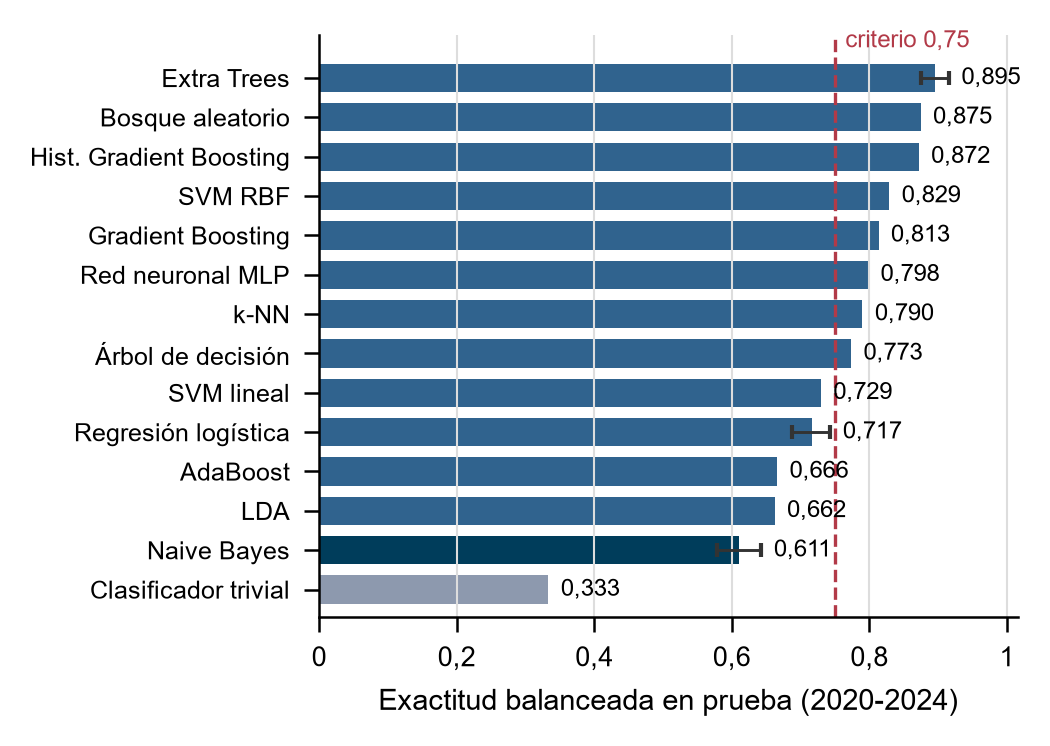

fig03_matrices_confusion.png


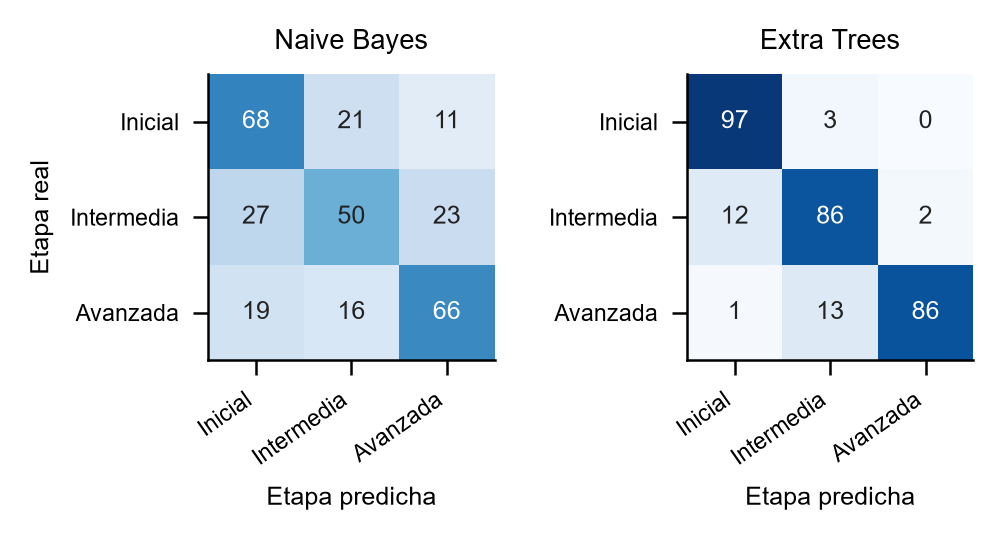

fig04_curvas_validacion.png


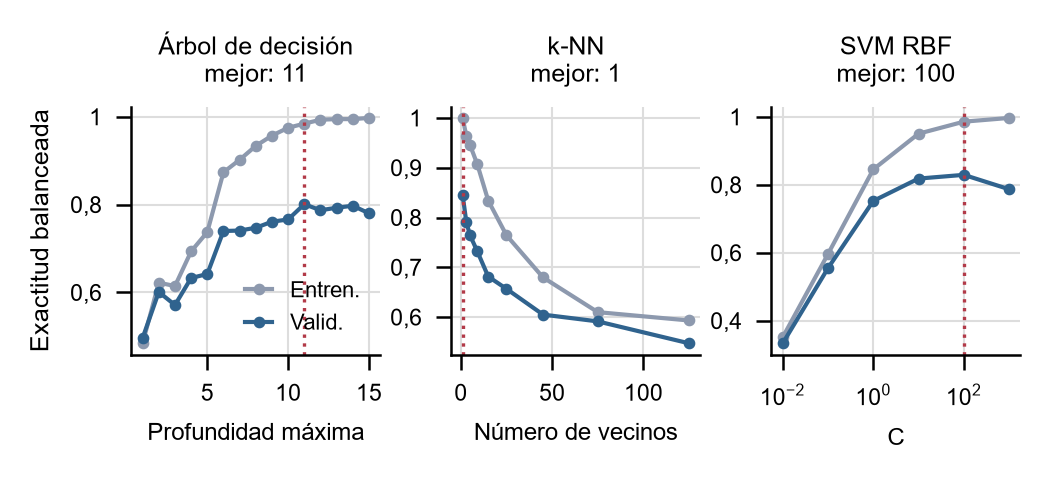

fig05_curvas_aprendizaje.png


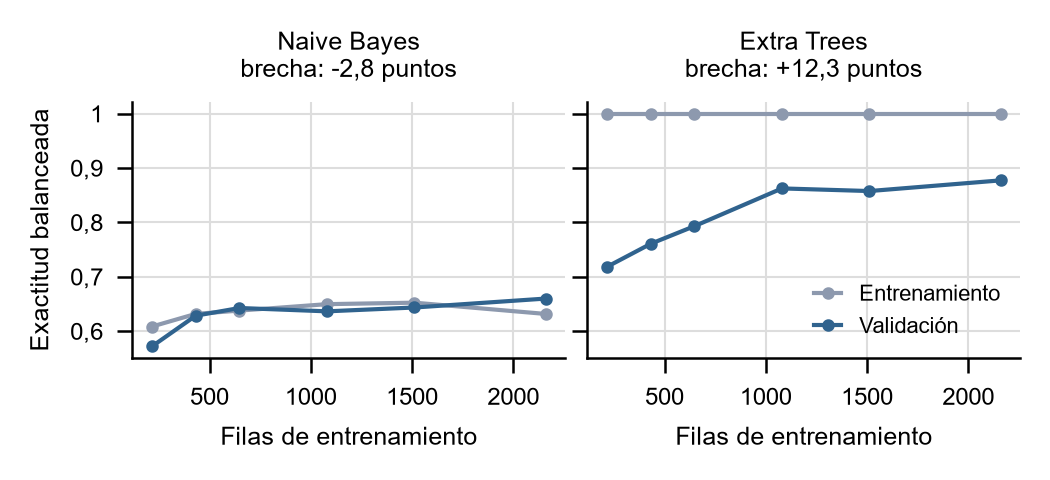

fig06_calibracion.png


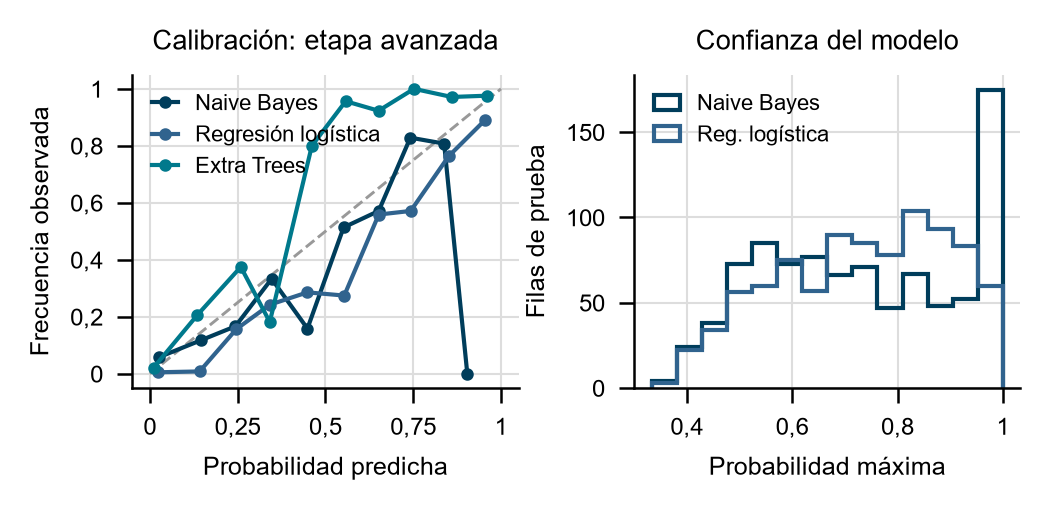

fig07_importancia_permutacion.png


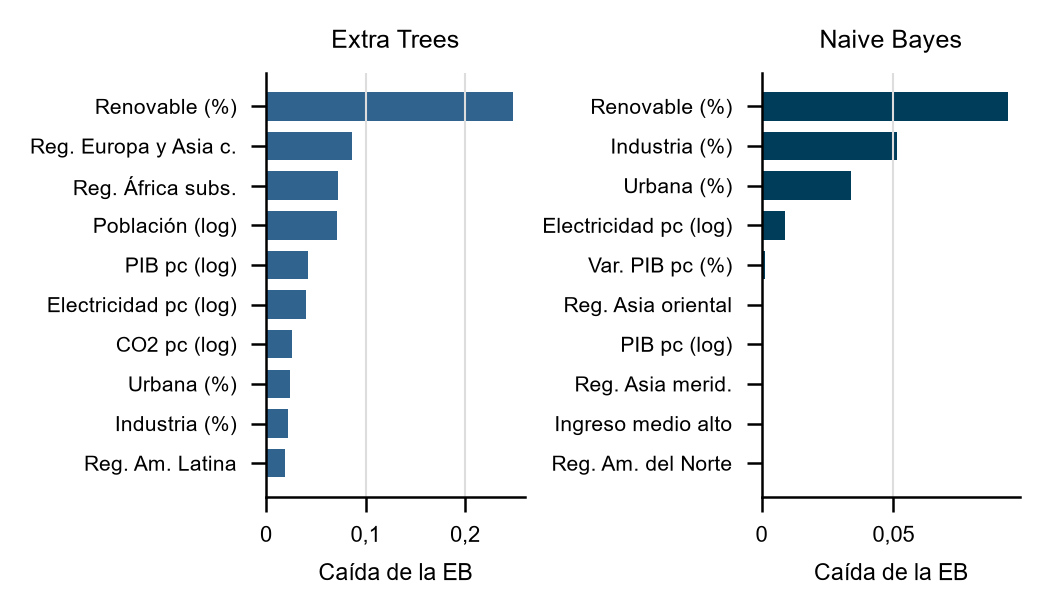

fig08_pca_tsne.png


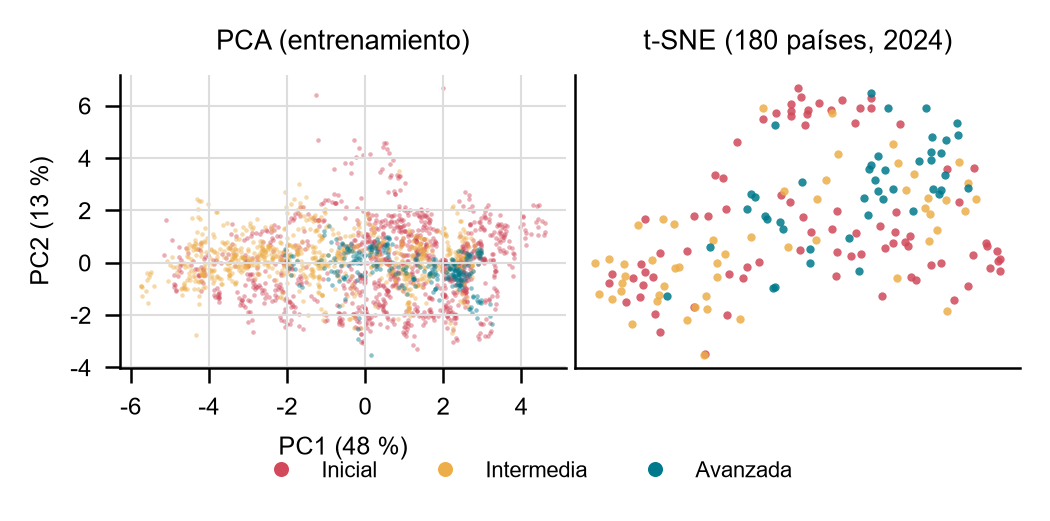

fig09_nmf_componentes.png


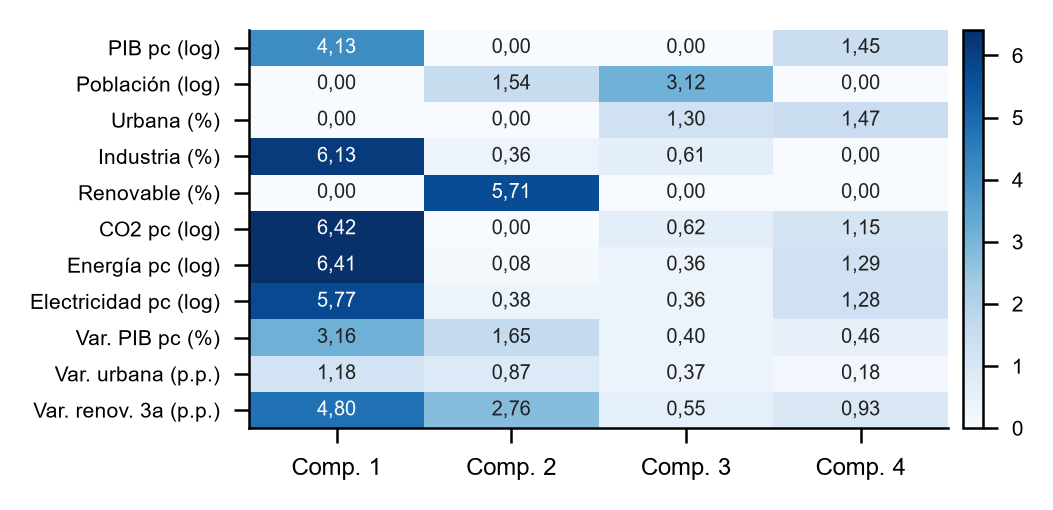

fig10_clustering.png


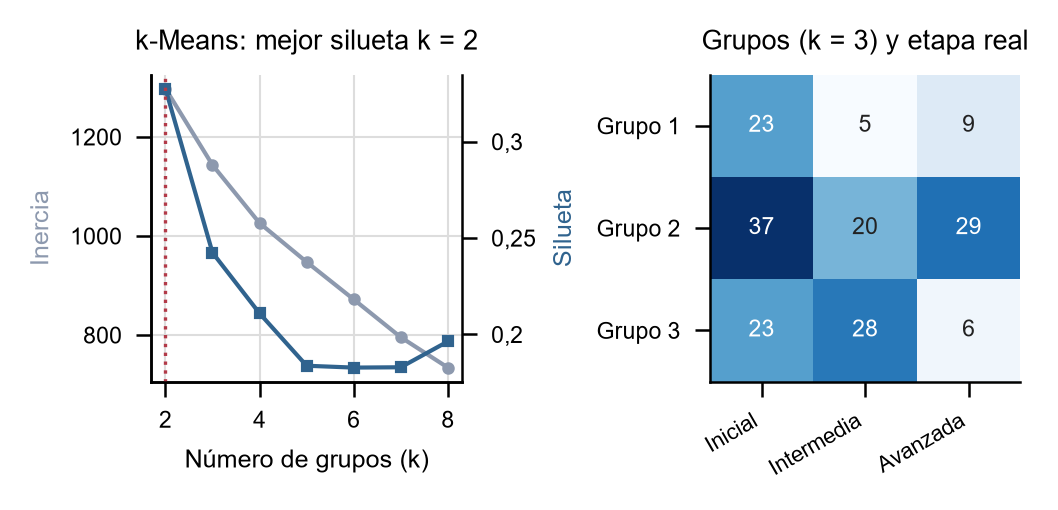

In [55]:
generar_figuras(modelado, evaluacion, capitulo2, capitulo3)
for archivo in sorted(CARPETA_FIGURAS.glob("fig*.png")):
    print(archivo.name)
    display(Image(filename=str(archivo)))

## Paso 9. Control de calidad y valores para el artículo
Los siete controles que CRISP-ML(Q) añade a CRISP-DM: si falla uno crítico, el programa se detiene. Después se escribe `valores_para_paper.md` con cada marcador del artículo y las cinco tablas.

In [56]:
# =============================================================================
# PASO 9. CONTROL DE CALIDAD (CRISP-ML(Q)) Y VALORES PARA EL ARTÍCULO
# =============================================================================
NUMEROS = {0: "Ninguno", 1: "Uno", 2: "Dos", 3: "Tres", 4: "Cuatro", 5: "Cinco",
           6: "Seis", 7: "Siete", 8: "Ocho", 9: "Nueve", 10: "Diez", 11: "Once",
           12: "Doce", 13: "Trece"}

In [57]:
def controles_calidad(datos: dict, modelado: dict) -> pd.DataFrame:
    """
    Aseguramiento de la calidad, que es lo que CRISP-ML(Q) añade a CRISP-DM.

    Son siete comprobaciones automáticas. Si falla una CRÍTICA, el programa se
    detiene con un mensaje claro en vez de publicar resultados que no se
    sostienen. La única que no detiene el programa es "todos superan al
    trivial": si algún modelo no lo supera, se informa, no se oculta.

    Resultado esperado: resultados/reportes/controles_calidad.csv con CUMPLE o
    NO CUMPLE en cada control.
    """
    seccion("PASO 9. CONTROL DE CALIDAD - CRISP-ML(Q)")
    df, comparacion = datos["df"], modelado["comparacion"]
    controles = []

    def anotar(clave, descripcion, cumple, detalle, critico=True):
        controles.append({"control": clave, "descripcion": descripcion,
                          "resultado": "CUMPLE" if cumple else "NO CUMPLE",
                          "detalle": detalle, "critico": "sí" if critico else "no"})
        nota(f"{clave}: {'CUMPLE' if cumple else 'NO CUMPLE'} - {detalle}")

    # C1. La práctica exige el modelo asignado y al menos otros diez.
    rivales = [m for m in ORDEN_MODELOS if m != MODELO_TRIVIAL]
    anotar("C1", "Al menos 11 modelos además del clasificador trivial",
           len(rivales) >= 11, f"{len(rivales)} modelos comparados")

    # C2. Ningún predictor puede identificar al país ni revelar la etiqueta.
    coladas = [c for c in PREDICTORES
               if c in PROHIBIDAS or c.startswith("bandera_imp_")
               or c in ("baja_carbono_elec_pct", "electricidad_pct", "b_promedio_3")]
    anotar("C2", "Ningún predictor prohibido (no hay fuga de la etiqueta)",
           not coladas, f"{len(PREDICTORES)} predictores revisados, 0 prohibidos"
           if not coladas else f"prohibidos: {coladas}")

    # C3. La evaluación respeta el tiempo: los años no se mezclan.
    rangos = {c: (int(df.loc[df["conjunto"] == c, "anio"].min()),
                  int(df.loc[df["conjunto"] == c, "anio"].max())) for c in ANIOS_CONJUNTO}
    sin_mezcla = (rangos == {c: tuple(v) for c, v in ANIOS_CONJUNTO.items()}
                  and rangos["entrenamiento"][1] < rangos["validacion"][0]
                  and rangos["validacion"][1] < rangos["prueba"][0])
    anotar("C3", "Los años de entrenamiento, validación y prueba no se mezclan",
           sin_mezcla, "2004-2015 / 2016-2019 / 2020-2024")

    # C4. La prueba se mira una sola vez por modelo: ninguno se eligió con ella.
    repetidos = {k: v for k, v in USOS_DE_PRUEBA.items() if v != 1}
    anotar("C4", "Cada modelo calculó sus métricas de prueba una sola vez",
           not repetidos, f"{len(USOS_DE_PRUEBA)} modelos y variantes, "
           f"1 medición cada uno" if not repetidos else f"repetidos: {repetidos}")

    # C5. Semillas fijas en todo lo que tiene azar.
    anotar("C5", "Semillas fijas en modelos, remuestreos y agrupamiento",
           SEMILLA == 42, f"semilla {SEMILLA} en scikit-learn, bootstrap y k-Means")

    # C6. No es crítico, pero hay que decirlo: ¿algún modelo no aprendió nada?
    eb_trivial = float(comparacion.loc[comparacion["modelo"] == MODELO_TRIVIAL,
                                       "eb_prueba"].iloc[0])
    flojos = [m for m, v in zip(comparacion["modelo"], comparacion["eb_prueba"])
              if m != MODELO_TRIVIAL and v <= eb_trivial]
    anotar("C6", "Todos los modelos superan al clasificador trivial", not flojos,
           f"trivial: {num(eb_trivial)}" if not flojos
           else f"no lo superan: {lista_y(flojos)}", critico=False)

    # C7. Reproducibilidad: se vuelve a entrenar cada modelo final con los mismos
    # hiperparámetros y debe dar exactamente la misma exactitud balanceada.
    diferencias = []
    for nombre in ORDEN_MODELOS:
        estimador = construir_modelos()[nombre][0]
        parametros = modelado["modelos"][nombre]["parametros"]
        repetido = clone(estimador).set_params(**parametros).fit(datos["X_tv"], datos["y_tv"])
        eb = balanced_accuracy_score(datos["y_pr"], repetido.predict(datos["X_pr"]))
        original = float(comparacion.loc[comparacion["modelo"] == nombre, "eb_prueba"].iloc[0])
        if abs(eb - original) > 1e-12:
            diferencias.append(f"{nombre} ({num(eb, 6)} vs {num(original, 6)})")
    anotar("C7", "Dos corridas dan exactamente las mismas métricas", not diferencias,
           f"{len(ORDEN_MODELOS)} modelos reentrenados sin diferencia"
           if not diferencias else f"difieren: {lista_y(diferencias)}")

    tabla = pd.DataFrame(controles)
    tabla.to_csv(CARPETA_REPORTES / "controles_calidad.csv", index=False, encoding="utf-8")
    nota("reporte guardado: resultados/reportes/controles_calidad.csv")

    fallidos = tabla[(tabla["resultado"] == "NO CUMPLE") & (tabla["critico"] == "sí")]
    if not fallidos.empty:
        raise SystemExit(
            "\nSE DETIENE EL PROGRAMA: no se cumplen controles críticos de calidad:\n"
            + "\n".join(f"  * {f.control}: {f.descripcion} -> {f.detalle}"
                        for f in fallidos.itertuples()))
    return tabla

In [58]:
def valores_para_paper(datos: dict, modelado: dict, evaluacion: dict,
                       capitulo2: dict, capitulo3: dict) -> dict:
    """
    Escribe resultados/reportes/valores_para_paper.md.

    El artículo se redactó con marcadores en lugar de cifras. Este archivo
    entrega cada marcador con su valor y con una explicación de cómo se calculó,
    además de las cinco tablas del artículo con sus filas en el mismo orden.
    Así nadie copia un número a mano desde la consola.
    """
    seccion("PASO 9 (fin). VALORES PARA EL ARTÍCULO")
    comparacion = modelado["comparacion"].set_index("modelo")
    mejor = evaluacion["mejor"]
    fila_mejor, fila_nb = comparacion.loc[mejor], comparacion.loc[MODELO_ASIGNADO]
    fila_rl = comparacion.loc[MODELO_LOGISTICA]
    ic_mejor, ic_nb = evaluacion["intervalos"][mejor], evaluacion["intervalos"][MODELO_ASIGNADO]

    # --- Variante ganadora del modelo asignado ------------------------------
    parametros_nb = modelado["modelos"][MODELO_ASIGNADO]["parametros"]
    usa_yeo = "PowerTransformer" in str(parametros_nb.get("transf", "passthrough"))
    usa_iguales = parametros_nb.get("modelo__priors") is not None
    suavizado = parametros_nb.get("modelo__var_smoothing", float("nan"))
    variante_nb = (f"{'Yeo-Johnson' if usa_yeo else 'sin transformación'} con priors "
                   f"{'iguales' if usa_iguales else 'de los datos'} "
                   f"(var_smoothing = {suavizado:.0e})")

    # --- Confusión más frecuente del mejor modelo ---------------------------
    matriz = evaluacion["confusiones"][mejor]
    fuera = [(matriz[i, j], i, j) for i in range(3) for j in range(3) if i != j]
    peso, real, predicha = max(fuera)
    confusion_principal = (f"{ETAPAS[real].lower()} predicha como {ETAPAS[predicha].lower()} "
                           f"({pct(peso)} de las {ETAPAS[real].lower()}s)")

    # --- Región con menor exactitud del mejor modelo ------------------------
    regiones = evaluacion["regiones"]
    peor = regiones.loc[regiones[mejor].idxmin()]
    region_peor = f"{peor['region']} ({num(peor[mejor])})"

    # --- Modelos que superan el criterio de éxito ---------------------------
    rivales = modelado["comparacion"][modelado["comparacion"]["modelo"] != MODELO_TRIVIAL]
    n_075 = int((rivales["eb_prueba"] >= CRITERIO_EXITO).sum())
    cumple_criterio = float(fila_mejor["eb_prueba"]) >= CRITERIO_EXITO

    # --- Capítulo 2: curvas y probabilidades --------------------------------
    curvas_v = capitulo2["validacion"]
    curvas_a = capitulo2["aprendizaje"]
    incertidumbre = capitulo2["incertidumbre"]
    escalado_tabla = capitulo3["escalado"].set_index("preprocesamiento")
    ganancia_knn = (escalado_tabla.loc["Estandarizado", "k-NN (k = 15)"]
                    - escalado_tabla.loc["Sin escalar", "k-NN (k = 15)"])

    # --- Capítulo 3: PCA, NMF y agrupamiento --------------------------------
    reduccion, agrupa = capitulo3["reduccion"], capitulo3["agrupamiento"]
    pesos = reduccion["pesos_nmf"]
    tabla_grupos = agrupa["tabla"].set_index("metodo")
    fila_dbscan = tabla_grupos.loc["DBSCAN"]
    nombre_km_silueta = f"k-Means (mejor silueta, k = {agrupa['k_silueta']})"

    def top3(nombre_modelo):
        return lista_y(list(evaluacion["importancias"][nombre_modelo]["nombre"].head(3)))

    mcnemar = evaluacion["mcnemar"]
    p_texto = "< 0,001" if mcnemar["p"] < 0.001 else num(mcnemar["p"])
    umbrales = evaluacion["umbrales"]
    ll_nb, ll_rl = float(fila_nb["log_loss"]), float(fila_rl["log_loss"])
    ext_nb = incertidumbre[MODELO_ASIGNADO]["extremas"]
    ext_rl = incertidumbre[MODELO_LOGISTICA]["extremas"]
    diferencia_nb = float(fila_mejor["eb_prueba"]) - float(fila_nb["eb_prueba"])

    # --- Frases: interpretan lo que de verdad salió -------------------------
    mejores_tres = [nombre_corto(m) for m in
                    modelado["comparacion"].nlargest(3, "eb_prueba")["modelo"]]
    peor_rival = nombre_corto(rivales.loc[rivales["eb_prueba"].idxmin(), "modelo"])
    mejor_calibrado = nombre_corto(rivales.loc[rivales["log_loss"].idxmin(), "modelo"])
    mas_rapido = nombre_corto(rivales.loc[rivales["segundos_entrenamiento"].idxmin(), "modelo"])
    segundos_nb = float(fila_nb["segundos_entrenamiento"])
    tiempo_nb = (f"{num(segundos_nb, 2)} segundos" if segundos_nb >= 0.01
                 else "menos de una centésima de segundo")
    ganancia_svm = (escalado_tabla.loc["Estandarizado", "SVM RBF (C = 10)"]
                    - escalado_tabla.loc["Sin escalar", "SVM RBF (C = 10)"])
    brecha_nb, brecha_mejor = curvas_a[MODELO_ASIGNADO]["brecha"], curvas_a[mejor]["brecha"]
    nb_peor_calibrado = ll_nb > ll_rl
    brecha_nb_texto = ("incluso negativa: no llega a sobreajustar, le falta capacidad"
                       if brecha_nb < 0 else "muy pequeña: apenas sobreajusta")
    rango_bosque = (escalado_tabla["Bosque aleatorio"].max()
                    - escalado_tabla["Bosque aleatorio"].min())
    ari_km3 = float(tabla_grupos.loc["k-Means (k = 3)", "ari"])

    frases = {
        "FRASE_COMPARACION": (
            f"Los tres mejores fueron {lista_y(mejores_tres)}, los tres ensambles de "
            f"árboles; el más bajo de los trece fue {peor_rival}, con "
            f"{num(float(rivales['eb_prueba'].min()))}."),
        "FRASE_VALIDACION": (
            f"En nuestros datos el árbol llega al máximo de validación con profundidad "
            f"{curvas_v['Árbol de decisión']['mejor']} y después sigue mejorando en "
            f"entrenamiento mientras la validación baja, que es sobreajuste; con "
            f"profundidad 1 o 2 los dos aciertos son bajos, que es subajuste."),
        "FRASE_APRENDIZAJE": (
            f"En Naive Bayes la brecha es {brecha_nb_texto}, mientras que "
            f"{nombre_corto(mejor)} memoriza el entrenamiento y, aun así, generaliza mucho "
            f"mejor. En los dos, la curva de validación casi no sube en la última mitad, "
            f"así que más años del mismo tipo no cambiarían mucho el resultado."),
        "FRASE_CALIBRACION": (
            f"Naive Bayes quedó {'peor' if nb_peor_calibrado else 'mejor'} calibrado que la "
            f"regresión logística: su pérdida logarítmica es "
            f"{num(ll_nb)} frente a {num(ll_rl)}, y se declara casi seguro "
            f"({pct(ext_nb)} de las filas por encima de 0,99) muchas más veces que ella "
            f"({pct(ext_rl)})."),
        "FRASE_ESCALADO": (
            f"A la SVM RBF el escalado le cambia la vida ({puntos(ganancia_svm)} puntos al "
            f"estandarizar); a k-NN con k = 15, en cambio, le sienta mal "
            f"({puntos(ganancia_knn)} puntos), porque al estandarizar las once indicadoras "
            f"de región y de ingreso pasan a pesar tanto como los indicadores continuos. El "
            f"bosque aleatorio se mueve apenas {num(rango_bosque)} entre el mejor y el peor "
            f"preprocesamiento."),
        "FRASE_PCA_TSNE": (
            f"las tres etapas se superponen: se ve un gradiente de desarrollo económico, "
            f"pero los países avanzados no forman una zona propia, porque la etiqueta "
            f"depende de la matriz eléctrica y esa variable no está entre los once "
            f"indicadores."),
        "FRASE_NB_DESEMPENO": (
            f"Con esa sencillez llegó a {num(float(fila_nb['eb_prueba']))} de exactitud "
            f"balanceada en prueba, {puntos(abs(diferencia_nb))[1:]} puntos "
            f"{'por debajo' if diferencia_nb > 0 else 'por encima'} de "
            f"{nombre_corto(mejor)}, y entrenarlo tomó {tiempo_nb}."),
        "EFECTO_VARIANTES_NB": "",     # se completa más abajo con la tabla de variantes
        "FRASE_VENTAJAS": (
            f"En nuestros datos el orden quedó claro: los ensambles de árboles ganan en "
            f"exactitud y además dan las probabilidades más creíbles "
            f"({mejor_calibrado} tiene la menor pérdida logarítmica), mientras que "
            f"{mas_rapido} es el más barato de entrenar."),
        "FRASE_CRITERIO": (
            f"Con {num(float(fila_mejor['eb_prueba']))} de exactitud balanceada, "
            f"{nombre_corto(mejor)} {'cumple' if cumple_criterio else 'no cumple'} el "
            f"criterio de 0,75 que nos fijamos, y reconoce el "
            f"{pct(float(fila_mejor['recall_avanzada']))} de los países avanzados."),
        "FRASE_CLUSTER": (
            f"el agrupamiento solo reproduce en parte las etapas (el mejor índice de Rand "
            f"ajustado es {num(max(tabla_grupos['ari']))}), así que la etiqueta no se "
            f"puede reemplazar por grupos encontrados sin ella."),
        "FRASE_CONCLUSION_NB": (
            f"Es {'un resultado inferior' if diferencia_nb > 0 else 'un resultado superior'} "
            f"al de {nombre_corto(mejor)}, con un entrenamiento de {tiempo_nb}; su límite "
            f"está en el supuesto de independencia y en unas probabilidades "
            f"{'mal' if nb_peor_calibrado else 'bien'} calibradas."),
    }

    # El efecto de las variantes se mide sobre la tabla de variantes de NB.
    variantes = modelado["variantes"]
    base = variantes.iloc[0]["eb_validacion"]
    ganadora = variantes.loc[variantes["eb_validacion"].idxmax()]
    otras = variantes.iloc[1:]["eb_validacion"]
    frases["EFECTO_VARIANTES_NB"] = (
        f"subieron la exactitud balanceada en validación de {num(base)} a "
        f"{num(float(ganadora['eb_validacion']))} "
        f"({puntos(float(ganadora['eb_validacion']) - base)} puntos)"
        if float(ganadora["eb_validacion"]) > base else
        f"no ayudaron: la variante sin transformación y con los priors de los datos siguió "
        f"siendo la mejor en validación ({num(base)}), y las otras tres se quedaron entre "
        f"{num(float(otras.min()))} y {num(float(otras.max()))}")

    marcadores = {
        "MEJOR": (mejor, "modelo con mayor exactitud balanceada en prueba, sin contar el trivial"),
        "EN_BEST": (NOMBRES_INGLES[mejor], "el mismo nombre en inglés, para la portada"),
        "BA_MEJOR": (num(float(fila_mejor["eb_prueba"])),
                     "exactitud balanceada del mejor modelo en 2020-2024"),
        "IC_MEJOR": (intervalo(*ic_mejor),
                     f"percentiles 2,5 y 97,5 de {REMUESTREOS} remuestreos bootstrap de las 900 filas de prueba"),
        "F1_MEJOR": (num(float(fila_mejor["f1_macro"])), "F1 macro del mejor modelo en prueba"),
        "BA_NB": (num(float(fila_nb["eb_prueba"])),
                  "exactitud balanceada de Naive Bayes final en prueba"),
        "IC_NB": (intervalo(*ic_nb), "bootstrap de 1 000 remuestreos, igual que el mejor modelo"),
        "BA_NB_VAL": (num(float(fila_nb["eb_validacion"])),
                      "exactitud balanceada de Naive Bayes en validación (2016-2019)"),
        "VARIANTE_NB": (variante_nb,
                        "combinación de la rejilla de Naive Bayes con mayor exactitud balanceada en validación"),
        "N_075": (NUMEROS.get(n_075, str(n_075)),
                  f"modelos (de 13, sin contar el trivial) con exactitud balanceada en prueba >= {num(CRITERIO_EXITO, 2)}"),
        "BA_TRIVIAL": (num(float(comparacion.loc[MODELO_TRIVIAL, "eb_prueba"])),
                       "exactitud balanceada en prueba del clasificador que siempre predice la etapa más frecuente"),
        "MCNEMAR": ("es significativa" if mcnemar["significativa"] else "no es significativa",
                    f"prueba exacta de McNemar con alfa = {num(ALFA, 2)} sobre los aciertos discordantes "
                    f"(b01 = {mcnemar['b01']}, b10 = {mcnemar['b10']})"),
        "P_MCNEMAR": (p_texto, "p-valor de la prueba exacta de McNemar"),
        "REC_AVA_NB": (pct(float(fila_nb["recall_avanzada"])),
                       "recall de la etapa avanzada en prueba, Naive Bayes"),
        "REC_AVA_MEJOR": (pct(float(fila_mejor["recall_avanzada"])),
                          "recall de la etapa avanzada en prueba, mejor modelo"),
        "CONFUSION_PRINCIPAL": (confusion_principal,
                                "celda fuera de la diagonal más grande de la matriz de confusión normalizada por fila"),
        "PROF_OPT": (str(curvas_v["Árbol de decisión"]["mejor"]),
                     "profundidad del árbol con mayor exactitud balanceada en validación"),
        "K_OPT": (str(curvas_v["k-NN"]["mejor"]), "número de vecinos con mayor EB en validación"),
        "C_OPT": (str(curvas_v["SVM RBF"]["mejor"]).replace(".", ","),
                  "C de la SVM RBF con mayor EB en validación"),
        "BRECHA_NB": (puntos(brecha_nb),
                      "(EB en entrenamiento - EB en validación) x 100 con todo el entrenamiento, Naive Bayes"),
        "BRECHA_MEJOR": (puntos(brecha_mejor), "lo mismo para el mejor modelo"),
        "LL_NB": (num(ll_nb), "pérdida logarítmica en prueba de Naive Bayes"),
        "LL_RL": (num(ll_rl), "pérdida logarítmica en prueba de la regresión logística"),
        "LL_MEJOR": (num(float(fila_mejor["log_loss"])), "pérdida logarítmica en prueba del mejor modelo"),
        "EXT_NB": (pct(ext_nb), "filas de prueba con probabilidad máxima > 0,99, Naive Bayes"),
        "EXT_RL": (pct(ext_rl), "lo mismo para la regresión logística"),
        "TOP3_MEJOR": (top3(mejor),
                       "tres variables con mayor caída de la EB al permutarlas (10 repeticiones) en el mejor modelo"),
        "TOP3_NB": (top3(MODELO_ASIGNADO), "lo mismo para Naive Bayes"),
        "ERR_UMBRAL": (pct(umbrales["errores_cerca"]),
                       f"errores del mejor modelo a menos de {UMBRAL_CERCA:.0f} puntos de los umbrales 30 %, 60 % o 90 % "
                       f"(sobre {umbrales['n_errores']} errores)"),
        "PRUEBA_UMBRAL": (pct(umbrales["prueba_cerca"]),
                          "mismo criterio, calculado sobre las 900 filas de prueba"),
        "REGION_PEOR": (region_peor, "región con menor exactitud del mejor modelo en prueba"),
        "GAN_KNN": (puntos(ganancia_knn),
                    "(EB de k-NN estandarizado - EB de k-NN sin escalar) x 100, en validación"),
        "PCA_2": (pct(float(reduccion["acumulada"][1])),
                  "varianza explicada por las dos primeras componentes de los 11 indicadores continuos"),
        "PCA_80": (str(reduccion["componentes_80"]), "componentes necesarias para llegar al 80 % de varianza"),
        "NMF_C1": (lista_y([legible(v) for v in pesos["C1"].nlargest(2).index]),
                   "las dos variables con mayor peso en el primer componente de NMF"),
        "NMF_C2": (lista_y([legible(v) for v in pesos["C2"].nlargest(2).index]),
                   "lo mismo para el segundo componente"),
        "K_SIL": (str(agrupa["k_silueta"]), "k con la mejor silueta en k-Means (k de 2 a 8), países de 2024"),
        "ARI_KM3": (num(ari_km3), "índice de Rand ajustado de k-Means con k = 3 frente a las etapas reales"),
        "ARI_WARD": (num(float(tabla_grupos.loc["Jerárquico Ward (k = 3)", "ari"])),
                     "lo mismo para el jerárquico de Ward con k = 3"),
        "ARI_DBSCAN": (num(float(fila_dbscan["ari"])), "lo mismo para DBSCAN"),
        "RUIDO_DBSCAN": (str(int(fila_dbscan["ruido"])), "países que DBSCAN marcó como ruido"),
        "CUMPLE": ("cumple" if cumple_criterio else "no cumple",
                   f"el mejor modelo frente al criterio de éxito de {num(CRITERIO_EXITO, 2)}"),
    }
    for clave, texto in frases.items():
        marcadores[clave] = (texto, "frase redactada con los resultados reales de esta corrida")

    # --- Las cinco tablas del artículo, en el orden del artículo ------------
    tabla4 = pd.DataFrame([{
        "Modelo": m, "EB-V": num(comparacion.loc[m, "eb_validacion"]),
        "EB-P": num(comparacion.loc[m, "eb_prueba"]),
        "F1-M": num(comparacion.loc[m, "f1_macro"]),
        "Exac.": num(comparacion.loc[m, "exactitud"]),
        "LL": num(comparacion.loc[m, "log_loss"]),
        "AUC": num(comparacion.loc[m, "auc_ovr_macro"])} for m in ORDEN_MODELOS])
    tabla5 = pd.DataFrame([{
        "Transformación": f["transformacion"], "Priors": f["priors"],
        "EB-V": num(f["eb_validacion"]), "EB-P": num(f["eb_prueba"]),
        "LL": num(f["log_loss"])} for _, f in variantes.iterrows()])
    tabla6 = pd.DataFrame([{
        "Región": f["region"], "Filas": int(f["filas"]),
        "Naive Bayes": num(f[MODELO_ASIGNADO]), "Mejor modelo": num(f[mejor])}
        for _, f in regiones.iterrows()])
    tabla7 = capitulo3["escalado"].copy()
    for columna in tabla7.columns[1:]:
        tabla7[columna] = tabla7[columna].map(num)
    tabla7 = tabla7.rename(columns={"preprocesamiento": "Preprocesamiento",
                                    "Bosque aleatorio": "Bosque aleat."})
    tabla8 = pd.DataFrame([{
        "Método": ("k-Means (k = 3)" if m == "k-Means (k = 3)" else
                   ("k-Means (mejor silueta)" if m == nombre_km_silueta else m)),
        "Grupos": int(f["grupos"]), "Ruido": int(f["ruido"]),
        "Silueta": num(f["silueta"]), "ARI": num(f["ari"]), "NMI": num(f["nmi"])}
        for m, f in tabla_grupos.iterrows()])

    lineas = [
        "# Valores para el artículo (Entregable 1)",
        "",
        "Generado por `main.py`. Cada marcador resaltado del artículo se reemplaza por el",
        "valor de la columna **Valor**. Los números usan coma decimal; las métricas van con",
        "tres decimales y los porcentajes con uno.",
        "",
        f"- scikit-learn {sklearn.__version__} · Python {platform.python_version()} · semilla {SEMILLA}",
        f"- Mejor modelo: **{mejor}** · Modelo asignado: **Naive Bayes gaussiano**",
        "",
        "## 1. Marcadores",
        "",
        "| Marcador | Valor | Cómo se calculó |",
        "|---|---|---|",
    ]
    for clave, (valor, explicacion) in marcadores.items():
        lineas.append(f"| `{clave}` | {valor} | {explicacion} |")
    lineas += [
        "", "## 2. Tabla IV · Desempeño en validación (2016-2019) y prueba (2020-2024)", "",
        tabla_md(tabla4),
        "", "EB-V y EB-P: exactitud balanceada en validación y en prueba; F1-M: F1 macro;",
        "Exac.: exactitud; LL: pérdida logarítmica; AUC: área bajo la curva ROC, una contra",
        "el resto, promedio macro. LL, F1-M, Exac. y AUC se miden en prueba.",
        "", "## 3. Tabla V · Variantes de Naive Bayes gaussiano", "",
        tabla_md(tabla5),
        "", "## 4. Tabla VI · Exactitud en prueba por región", "",
        tabla_md(tabla6),
        "", "## 5. Tabla VII · Exactitud balanceada en validación según el preprocesamiento", "",
        tabla_md(tabla7),
        "", "## 6. Tabla VIII · Agrupamiento de los 180 países en 2024 frente a las etapas", "",
        tabla_md(tabla8),
        f"", f"DBSCAN se ejecutó con eps = {str(agrupa['eps']).replace('.', ',')} y min_samples = 5.",
        "", "## 7. Figuras", "",
        "Las nueve figuras están en `resultados/figuras/` con el nombre que las cita el",
        "artículo (fig02 a fig10), a 3,35 pulgadas de ancho y 300 ppp.",
        "",
    ]
    (CARPETA_REPORTES / "valores_para_paper.md").write_text("\n".join(lineas), encoding="utf-8")
    nota("reporte guardado: resultados/reportes/valores_para_paper.md")
    return marcadores

In [59]:
def control_calidad_y_valores(datos, modelado, evaluacion, capitulo2, capitulo3):
    """Ejecuta los controles de CRISP-ML(Q) y, si pasan, escribe los valores del artículo."""
    controles = controles_calidad(datos, modelado)
    marcadores = valores_para_paper(datos, modelado, evaluacion, capitulo2, capitulo3)
    return controles, marcadores

Controles de calidad y archivo de valores para el artículo.

In [60]:
controles, marcadores = control_calidad_y_valores(
    datos, modelado, evaluacion, capitulo2, capitulo3)
display(controles[["control", "descripcion", "resultado"]])
display(Markdown((CARPETA_REPORTES / "valores_para_paper.md").read_text(encoding="utf-8")))


 PASO 9. CONTROL DE CALIDAD - CRISP-ML(Q)
   - C1: CUMPLE - 13 modelos comparados
   - C2: CUMPLE - 23 predictores revisados, 0 prohibidos
   - C3: CUMPLE - 2004-2015 / 2016-2019 / 2020-2024
   - C4: CUMPLE - 18 modelos y variantes, 1 medición cada uno
   - C5: CUMPLE - semilla 42 en scikit-learn, bootstrap y k-Means
   - C6: CUMPLE - trivial: 0,333


   - C7: CUMPLE - 14 modelos reentrenados sin diferencia
   - reporte guardado: resultados/reportes/controles_calidad.csv

 PASO 9 (fin). VALORES PARA EL ARTÍCULO
   - reporte guardado: resultados/reportes/valores_para_paper.md


,control,descripcion,resultado
0,C1,Al menos 11 modelos además del clasificador tr...,CUMPLE
1,C2,Ningún predictor prohibido (no hay fuga de la ...,CUMPLE
2,C3,"Los años de entrenamiento, validación y prueba...",CUMPLE
3,C4,Cada modelo calculó sus métricas de prueba una...,CUMPLE
4,C5,"Semillas fijas en modelos, remuestreos y agrup...",CUMPLE
5,C6,Todos los modelos superan al clasificador trivial,CUMPLE
6,C7,Dos corridas dan exactamente las mismas métricas,CUMPLE


# Valores para el artículo (Entregable 1)

Generado por `main.py`. Cada marcador resaltado del artículo se reemplaza por el
valor de la columna **Valor**. Los números usan coma decimal; las métricas van con
tres decimales y los porcentajes con uno.

- scikit-learn 1.9.1 · Python 3.12.2 · semilla 42
- Mejor modelo: **Extra Trees** · Modelo asignado: **Naive Bayes gaussiano**

## 1. Marcadores

| Marcador | Valor | Cómo se calculó |
|---|---|---|
| `MEJOR` | Extra Trees | modelo con mayor exactitud balanceada en prueba, sin contar el trivial |
| `EN_BEST` | Extra Trees | el mismo nombre en inglés, para la portada |
| `BA_MEJOR` | 0,895 | exactitud balanceada del mejor modelo en 2020-2024 |
| `IC_MEJOR` | 0,875–0,916 | percentiles 2,5 y 97,5 de 1000 remuestreos bootstrap de las 900 filas de prueba |
| `F1_MEJOR` | 0,903 | F1 macro del mejor modelo en prueba |
| `BA_NB` | 0,611 | exactitud balanceada de Naive Bayes final en prueba |
| `IC_NB` | 0,579–0,643 | bootstrap de 1 000 remuestreos, igual que el mejor modelo |
| `BA_NB_VAL` | 0,660 | exactitud balanceada de Naive Bayes en validación (2016-2019) |
| `VARIANTE_NB` | sin transformación con priors de los datos (var_smoothing = 1e-02) | combinación de la rejilla de Naive Bayes con mayor exactitud balanceada en validación |
| `N_075` | Ocho | modelos (de 13, sin contar el trivial) con exactitud balanceada en prueba >= 0,75 |
| `BA_TRIVIAL` | 0,333 | exactitud balanceada en prueba del clasificador que siempre predice la etapa más frecuente |
| `MCNEMAR` | es significativa | prueba exacta de McNemar con alfa = 0,05 sobre los aciertos discordantes (b01 = 290, b10 = 28) |
| `P_MCNEMAR` | < 0,001 | p-valor de la prueba exacta de McNemar |
| `REC_AVA_NB` | 65,5 % | recall de la etapa avanzada en prueba, Naive Bayes |
| `REC_AVA_MEJOR` | 86,4 % | recall de la etapa avanzada en prueba, mejor modelo |
| `CONFUSION_PRINCIPAL` | avanzada predicha como intermedia (12,6 % de las avanzadas) | celda fuera de la diagonal más grande de la matriz de confusión normalizada por fila |
| `PROF_OPT` | 11 | profundidad del árbol con mayor exactitud balanceada en validación |
| `K_OPT` | 1 | número de vecinos con mayor EB en validación |
| `C_OPT` | 100 | C de la SVM RBF con mayor EB en validación |
| `BRECHA_NB` | -2,8 | (EB en entrenamiento - EB en validación) x 100 con todo el entrenamiento, Naive Bayes |
| `BRECHA_MEJOR` | +12,3 | lo mismo para el mejor modelo |
| `LL_NB` | 1,068 | pérdida logarítmica en prueba de Naive Bayes |
| `LL_RL` | 0,690 | pérdida logarítmica en prueba de la regresión logística |
| `LL_MEJOR` | 0,337 | pérdida logarítmica en prueba del mejor modelo |
| `EXT_NB` | 6,8 % | filas de prueba con probabilidad máxima > 0,99, Naive Bayes |
| `EXT_RL` | 2,1 % | lo mismo para la regresión logística |
| `TOP3_MEJOR` | Energía renovable (%), Región: Europa y Asia central y Región: África subsahariana | tres variables con mayor caída de la EB al permutarlas (10 repeticiones) en el mejor modelo |
| `TOP3_NB` | Energía renovable (%), Industria (% del PIB) y Población urbana (%) | lo mismo para Naive Bayes |
| `ERR_UMBRAL` | 54,9 % | errores del mejor modelo a menos de 5 puntos de los umbrales 30 %, 60 % o 90 % (sobre 82 errores) |
| `PRUEBA_UMBRAL` | 16,1 % | mismo criterio, calculado sobre las 900 filas de prueba |
| `REGION_PEOR` | Asia oriental y el Pacífico (0,852) | región con menor exactitud del mejor modelo en prueba |
| `GAN_KNN` | -3,8 | (EB de k-NN estandarizado - EB de k-NN sin escalar) x 100, en validación |
| `PCA_2` | 60,7 % | varianza explicada por las dos primeras componentes de los 11 indicadores continuos |
| `PCA_80` | 5 | componentes necesarias para llegar al 80 % de varianza |
| `NMF_C1` | CO2 per cápita (log) y Energía per cápita (log) | las dos variables con mayor peso en el primer componente de NMF |
| `NMF_C2` | Energía renovable (%) y Variación renovable de 3 años (p.p.) | lo mismo para el segundo componente |
| `K_SIL` | 2 | k con la mejor silueta en k-Means (k de 2 a 8), países de 2024 |
| `ARI_KM3` | 0,028 | índice de Rand ajustado de k-Means con k = 3 frente a las etapas reales |
| `ARI_WARD` | 0,036 | lo mismo para el jerárquico de Ward con k = 3 |
| `ARI_DBSCAN` | -0,002 | lo mismo para DBSCAN |
| `RUIDO_DBSCAN` | 11 | países que DBSCAN marcó como ruido |
| `CUMPLE` | cumple | el mejor modelo frente al criterio de éxito de 0,75 |
| `FRASE_COMPARACION` | Los tres mejores fueron Extra Trees, Bosque aleatorio y Hist. Gradient Boosting, los tres ensambles de árboles; el más bajo de los trece fue Naive Bayes, con 0,611. | frase redactada con los resultados reales de esta corrida |
| `FRASE_VALIDACION` | En nuestros datos el árbol llega al máximo de validación con profundidad 11 y después sigue mejorando en entrenamiento mientras la validación baja, que es sobreajuste; con profundidad 1 o 2 los dos aciertos son bajos, que es subajuste. | frase redactada con los resultados reales de esta corrida |
| `FRASE_APRENDIZAJE` | En Naive Bayes la brecha es incluso negativa: no llega a sobreajustar, le falta capacidad, mientras que Extra Trees memoriza el entrenamiento y, aun así, generaliza mucho mejor. En los dos, la curva de validación casi no sube en la última mitad, así que más años del mismo tipo no cambiarían mucho el resultado. | frase redactada con los resultados reales de esta corrida |
| `FRASE_CALIBRACION` | Naive Bayes quedó peor calibrado que la regresión logística: su pérdida logarítmica es 1,068 frente a 0,690, y se declara casi seguro (6,8 % de las filas por encima de 0,99) muchas más veces que ella (2,1 %). | frase redactada con los resultados reales de esta corrida |
| `FRASE_ESCALADO` | A la SVM RBF el escalado le cambia la vida (+16,6 puntos al estandarizar); a k-NN con k = 15, en cambio, le sienta mal (-3,8 puntos), porque al estandarizar las once indicadoras de región y de ingreso pasan a pesar tanto como los indicadores continuos. El bosque aleatorio se mueve apenas 0,002 entre el mejor y el peor preprocesamiento. | frase redactada con los resultados reales de esta corrida |
| `FRASE_PCA_TSNE` | las tres etapas se superponen: se ve un gradiente de desarrollo económico, pero los países avanzados no forman una zona propia, porque la etiqueta depende de la matriz eléctrica y esa variable no está entre los once indicadores. | frase redactada con los resultados reales de esta corrida |
| `FRASE_NB_DESEMPENO` | Con esa sencillez llegó a 0,611 de exactitud balanceada en prueba, 28,5 puntos por debajo de Extra Trees, y entrenarlo tomó menos de una centésima de segundo. | frase redactada con los resultados reales de esta corrida |
| `EFECTO_VARIANTES_NB` | no ayudaron: la variante sin transformación y con los priors de los datos siguió siendo la mejor en validación (0,660), y las otras tres se quedaron entre 0,620 y 0,630 | frase redactada con los resultados reales de esta corrida |
| `FRASE_VENTAJAS` | En nuestros datos el orden quedó claro: los ensambles de árboles ganan en exactitud y además dan las probabilidades más creíbles (Extra Trees tiene la menor pérdida logarítmica), mientras que Naive Bayes es el más barato de entrenar. | frase redactada con los resultados reales de esta corrida |
| `FRASE_CRITERIO` | Con 0,895 de exactitud balanceada, Extra Trees cumple el criterio de 0,75 que nos fijamos, y reconoce el 86,4 % de los países avanzados. | frase redactada con los resultados reales de esta corrida |
| `FRASE_CLUSTER` | el agrupamiento solo reproduce en parte las etapas (el mejor índice de Rand ajustado es 0,044), así que la etiqueta no se puede reemplazar por grupos encontrados sin ella. | frase redactada con los resultados reales de esta corrida |
| `FRASE_CONCLUSION_NB` | Es un resultado inferior al de Extra Trees, con un entrenamiento de menos de una centésima de segundo; su límite está en el supuesto de independencia y en unas probabilidades mal calibradas. | frase redactada con los resultados reales de esta corrida |

## 2. Tabla IV · Desempeño en validación (2016-2019) y prueba (2020-2024)

| Modelo | EB-V | EB-P | F1-M | Exac. | LL | AUC |
|---|---|---|---|---|---|---|
| Naive Bayes (base) | 0,660 | 0,611 | 0,603 | 0,618 | 1,068 | 0,765 |
| Regresión logística | 0,724 | 0,717 | 0,691 | 0,708 | 0,690 | 0,862 |
| k-NN | 0,812 | 0,790 | 0,800 | 0,813 | 2,822 | 0,921 |
| Árbol de decisión | 0,795 | 0,773 | 0,783 | 0,799 | 7,249 | 0,833 |
| Bosque aleatorio | 0,861 | 0,875 | 0,879 | 0,886 | 0,367 | 0,966 |
| Extra Trees | 0,877 | 0,895 | 0,903 | 0,909 | 0,337 | 0,972 |
| Gradient Boosting | 0,808 | 0,813 | 0,821 | 0,830 | 0,434 | 0,946 |
| Hist. Gradient Boosting | 0,872 | 0,872 | 0,875 | 0,882 | 0,363 | 0,966 |
| AdaBoost | 0,663 | 0,666 | 0,675 | 0,689 | 1,066 | 0,856 |
| SVM RBF | 0,845 | 0,829 | 0,838 | 0,850 | 0,467 | 0,937 |
| SVM lineal | 0,754 | 0,729 | 0,716 | 0,729 | 0,618 | 0,880 |
| LDA | 0,693 | 0,662 | 0,664 | 0,691 | 0,690 | 0,858 |
| Red neuronal MLP | 0,771 | 0,798 | 0,805 | 0,813 | 0,524 | 0,932 |
| Clasificador trivial | 0,333 | 0,333 | 0,211 | 0,463 | 19,343 | 0,500 |

EB-V y EB-P: exactitud balanceada en validación y en prueba; F1-M: F1 macro;
Exac.: exactitud; LL: pérdida logarítmica; AUC: área bajo la curva ROC, una contra
el resto, promedio macro. LL, F1-M, Exac. y AUC se miden en prueba.

## 3. Tabla V · Variantes de Naive Bayes gaussiano

| Transformación | Priors | EB-V | EB-P | LL |
|---|---|---|---|---|
| Ninguna | De los datos | 0,660 | 0,611 | 1,068 |
| Ninguna | Iguales | 0,626 | 0,633 | 2,298 |
| Yeo-Johnson | De los datos | 0,630 | 0,659 | 2,664 |
| Yeo-Johnson | Iguales | 0,620 | 0,628 | 2,847 |

## 4. Tabla VI · Exactitud en prueba por región

| Región | Filas | Naive Bayes | Mejor modelo |
|---|---|---|---|
| África subsahariana | 220 | 0,641 | 0,936 |
| América Latina y el Caribe | 170 | 0,629 | 0,953 |
| América del Norte | 15 | 0,667 | 1,000 |
| Asia oriental y el Pacífico | 135 | 0,541 | 0,852 |
| Asia meridional | 30 | 0,400 | 0,900 |
| Europa y Asia central | 230 | 0,565 | 0,857 |
| Medio Oriente y norte de África | 100 | 0,830 | 0,960 |

## 5. Tabla VII · Exactitud balanceada en validación según el preprocesamiento

| Preprocesamiento | k-NN (k = 15) | SVM RBF (C = 10) | Bosque aleat. |
|---|---|---|---|
| Sin escalar | 0,719 | 0,652 | 0,836 |
| Estandarizado | 0,681 | 0,818 | 0,839 |
| Mínimo-máximo | 0,684 | 0,804 | 0,836 |
| Robusto | 0,654 | 0,798 | 0,836 |
| Yeo-Johnson | 0,711 | 0,823 | 0,839 |

## 6. Tabla VIII · Agrupamiento de los 180 países en 2024 frente a las etapas

| Método | Grupos | Ruido | Silueta | ARI | NMI |
|---|---|---|---|---|---|
| k-Means (k = 3) | 3 | 0 | 0,242 | 0,028 | 0,059 |
| k-Means (mejor silueta) | 2 | 0 | 0,328 | 0,044 | 0,055 |
| Jerárquico Ward (k = 3) | 3 | 0 | 0,218 | 0,036 | 0,062 |
| DBSCAN | 1 | 11 | - | -0,002 | 0,033 |

DBSCAN se ejecutó con eps = 2,75 y min_samples = 5.

## 7. Figuras

Las nueve figuras están en `resultados/figuras/` con el nombre que las cita el
artículo (fig02 a fig10), a 3,35 pulgadas de ancho y 300 ppp.


## Paso 10. Flujo principal
En `main.py` la función `principal()` encadena todos los pasos. En el notebook ya los ejecutamos uno por uno, así que esta celda solo define la función; no hace falta llamarla.

In [61]:
# =============================================================================
# PASO 10. FLUJO PRINCIPAL
# =============================================================================
def principal(argumentos: list | None = None) -> int:
    """
    Ejecuta las dos fases de CRISP-ML(Q) y los dos capítulos de la guía, en orden.

    Cada paso usa lo que produjo el anterior; al final quedan las tablas, las
    figuras y el archivo de valores que necesita el artículo.
    """
    lector = argparse.ArgumentParser(
        description="Grupo 7 - CRISP-ML(Q) fases 4 y 5: modelado y evaluación")
    lector.add_argument("--rapido", action="store_true",
                        help="rejillas reducidas, solo para comprobar que todo corre")
    lector.add_argument("--n-jobs", type=int, default=1,
                        help="núcleos para la búsqueda en rejilla (1 por defecto)")
    args = lector.parse_args(argumentos)

    inicio = time.perf_counter()
    preparar_carpetas()
    datos = cargar_datos()
    modelado = fase4_modelado(datos, args.rapido, args.n_jobs)
    evaluacion = fase5_evaluacion(datos, modelado, args.n_jobs)
    capitulo2 = capitulo2_supervisado(datos, modelado, evaluacion["mejor"])
    capitulo3 = capitulo3_no_supervisado(datos)
    generar_figuras(modelado, evaluacion, capitulo2, capitulo3)
    control_calidad_y_valores(datos, modelado, evaluacion, capitulo2, capitulo3)

    seccion("RESUMEN")
    comparacion = modelado["comparacion"].set_index("modelo")
    nota(f"mejor modelo: {evaluacion['mejor']} "
         f"(exactitud balanceada en prueba {num(comparacion.loc[evaluacion['mejor'], 'eb_prueba'])})")
    nota(f"modelo asignado (Naive Bayes): "
         f"{num(comparacion.loc[MODELO_ASIGNADO, 'eb_prueba'])}")
    nota(f"criterio de éxito de {num(CRITERIO_EXITO, 2)}: "
         f"{'CUMPLE' if comparacion.loc[evaluacion['mejor'], 'eb_prueba'] >= CRITERIO_EXITO else 'NO CUMPLE'}")
    nota("tablas en resultados/tablas, figuras en resultados/figuras, "
         "controles y valores en resultados/reportes")
    nota(f"tiempo total: {time.perf_counter() - inicio:.1f} s")
    return 0